<a href="https://colab.research.google.com/github/famub/2026-GP1-02/blob/main/EfficientNetB5_KneeOA_5class.new.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/saraalshalaan/2026-GP1-02/blob/main/EfficientNetB5_KneeOA_5class.ipynb)


In [1]:
!pip install kagglehub
import kagglehub
path = kagglehub.dataset_download("shashwatwork/knee-osteoarthritis-dataset-with-severity")
print("Path to dataset files:", path)


Using Colab cache for faster access to the 'knee-osteoarthritis-dataset-with-severity' dataset.
Path to dataset files: /kaggle/input/knee-osteoarthritis-dataset-with-severity


In [2]:
!ls {path}

auto_test  test  train	val


In [3]:
from torchvision import transforms, datasets

base = path

tf = transforms.Compose([
    transforms.Grayscale(3),
    transforms.Resize((224,224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])
])

train = datasets.ImageFolder(f"{base}/train", transform=tf)
val   = datasets.ImageFolder(f"{base}/val",   transform=tf)
test  = datasets.ImageFolder(f"{base}/test",  transform=tf)

print("train:", len(train), "| val:", len(val), "| test:", len(test))
print("classes:", train.classes)


train: 5778 | val: 826 | test: 1656
classes: ['0', '1', '2', '3', '4']


In [4]:
from collections import Counter

for name, ds in [("train", train), ("val", val), ("test", test)]:
    counts = Counter(ds.targets)
    print(name, {ds.classes[k]: v for k, v in sorted(counts.items())})


train {'0': 2286, '1': 1046, '2': 1516, '3': 757, '4': 173}
val {'0': 328, '1': 153, '2': 212, '3': 106, '4': 27}
test {'0': 639, '1': 296, '2': 447, '3': 223, '4': 51}


In [5]:
import torch

counts = Counter(train.targets)
total = sum(counts.values())
weights = [total / (5 * counts[i]) for i in range(5)]
class_weights = torch.tensor(weights, dtype=torch.float)

print("class weights:", [round(w, 2) for w in weights])


class weights: [0.51, 1.1, 0.76, 1.53, 6.68]


In [6]:
train_tf = transforms.Compose([
    transforms.Grayscale(3),
    transforms.Resize((224,224)),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])
])

train = datasets.ImageFolder(f"{base}/train", transform=train_tf)
print("train:", len(train))


train: 5778


In [7]:
from torch.utils.data import DataLoader

val = datasets.ImageFolder(f"{base}/val", transform=tf)
test = datasets.ImageFolder(f"{base}/test", transform=tf)

train_loader = DataLoader(train, batch_size=32, shuffle=True)
val_loader = DataLoader(val, batch_size=32, shuffle=False)
test_loader = DataLoader(test, batch_size=32, shuffle=False)

images, labels = next(iter(train_loader))
print("batch shape:", images.shape)
print("labels:", labels[:10])


batch shape: torch.Size([32, 3, 224, 224])
labels: tensor([0, 3, 3, 0, 2, 0, 0, 1, 2, 2])


In [8]:
import cv2
import numpy as np
from PIL import Image
from torch.utils.data import DataLoader

# 1) دالة التنظيف: noise reduction + تحسين التباين
class Denoise:
    def __call__(self, img):
        g = np.array(img.convert("L"))                      # رمادي
        g = cv2.GaussianBlur(g, (3, 3), 0)                  # إزالة الضوضاء
        g = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(g)  # تحسين التباين
        return Image.fromarray(g)

# 2) pipeline للـ val و test (بدون augmentation)
tf = transforms.Compose([
    Denoise(),
    transforms.Grayscale(3),
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

# 3) pipeline للـ train (مع augmentation)
train_tf = transforms.Compose([
    Denoise(),
    transforms.Grayscale(3),
    transforms.Resize((224, 224)),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

# 4) نعيد تحميل الداتا بالـ pipeline الجديد
train = datasets.ImageFolder(f"{base}/train", transform=train_tf)
val   = datasets.ImageFolder(f"{base}/val",   transform=tf)
test  = datasets.ImageFolder(f"{base}/test",  transform=tf)

train_loader = DataLoader(train, batch_size=32, shuffle=True)
val_loader   = DataLoader(val,   batch_size=32, shuffle=False)
test_loader  = DataLoader(test,  batch_size=32, shuffle=False)

images, labels = next(iter(train_loader))
print("batch shape:", images.shape)
print("train:", len(train), "| val:", len(val), "| test:", len(test))


batch shape: torch.Size([32, 3, 224, 224])
train: 5778 | val: 826 | test: 1656


In [9]:
import os
for dp, dn, fn in os.walk(path):
    depth = dp[len(path):].count(os.sep)
    if depth <= 2:
        print("  " * depth + os.path.basename(dp) + "/", f"({len(fn)} files)" if fn else "")


knee-osteoarthritis-dataset-with-severity/ 
  auto_test/ 
    2/ (403 files)
    0/ (604 files)
    3/ (200 files)
    1/ (275 files)
    4/ (44 files)
  val/ 
    2/ (212 files)
    0/ (328 files)
    3/ (106 files)
    1/ (153 files)
    4/ (27 files)
  test/ 
    2/ (447 files)
    0/ (639 files)
    3/ (223 files)
    1/ (296 files)
    4/ (51 files)
  train/ 
    2/ (1516 files)
    0/ (2286 files)
    3/ (757 files)
    1/ (1046 files)
    4/ (173 files)


In [10]:
from torchvision import transforms, datasets
import os, re

# ---- find the folder that contains train / val / test (works whatever the nesting is) ----
def find_base(root):
    for dp, dn, _ in os.walk(root):
        if {"train", "val", "test"} <= set(dn):
            return dp
    raise FileNotFoundError("train/val/test folders not found under " + root)

base = find_base(path)
print("base:", base)          # NOTE: 'auto_test' (if it exists) is NOT used

# ---- choose the task ----------------------------------------------------------------------
# "5class" : KL 0,1,2,3,4 (normal 5-class task)
# "merge01": KL 0+1 merged -> 4 classes  (0-1 | 2 | 3 | 4)
# "binary" : KL 0+1 vs KL>=2 (clinically relevant OA yes/no)
# "drop01" : REMOVE KL 0 and 1 completely -> 3 classes (2 | 3 | 4)  (different, easier task!)
MODE = "5class"   # all grades KL0-KL4

MODES = {
    "5class":  ({0: 0, 1: 1, 2: 2, 3: 3, 4: 4},          ["KL0", "KL1", "KL2", "KL3", "KL4"]),
    "merge01": ({0: 0, 1: 0, 2: 1, 3: 2, 4: 3},          ["KL0-1", "KL2", "KL3", "KL4"]),
    "binary":  ({0: 0, 1: 0, 2: 1, 3: 1, 4: 1},          ["KL0-1", "KL2-4"]),
    "drop01":  ({0: None, 1: None, 2: 0, 3: 1, 4: 2},    ["KL2", "KL3", "KL4"]),
}
LABEL_MAP, CLASS_NAMES = MODES[MODE]
NUM_CLASSES = len(CLASS_NAMES)

def remap(ds):
    """Re-label (or drop) samples of a freshly loaded ImageFolder according to MODE."""
    folder_names = ds.classes                       # e.g. ['0','1','2','3','4']
    samples = []
    for p, c in ds.samples:
        grade = int(re.match(r"\d", folder_names[c]).group())   # KL grade from the folder name
        new = LABEL_MAP[grade]
        if new is not None:
            samples.append((p, new))
    ds.samples = ds.imgs = samples
    ds.targets = [t for _, t in samples]
    ds.classes = CLASS_NAMES
    ds.class_to_idx = {n: i for i, n in enumerate(CLASS_NAMES)}

# Resolution. (If the check below prints 224x224, 224 is the fastest option.)
IMG_SIZE = 224   # fastest. (300 = ~2x slower, only worth it if accuracy is still low)

tf = transforms.Compose([
    transforms.Grayscale(3),
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])
])

train = datasets.ImageFolder(f"{base}/train", transform=tf)
val   = datasets.ImageFolder(f"{base}/val",   transform=tf)
test  = datasets.ImageFolder(f"{base}/test",  transform=tf)
print("folders found:", train.classes)
for ds in (train, val, test):
    remap(ds)

from PIL import Image
print("original image size:", Image.open(train.samples[0][0]).size)
print("MODE:", MODE, "| classes:", train.classes)
print("train:", len(train), "| val:", len(val), "| test:", len(test))


base: /kaggle/input/knee-osteoarthritis-dataset-with-severity
folders found: ['0', '1', '2', '3', '4']
original image size: (224, 224)
MODE: 5class | classes: ['KL0', 'KL1', 'KL2', 'KL3', 'KL4']
train: 5778 | val: 826 | test: 1656


In [11]:
# Leakage check: are there byte-identical images shared between splits?
import hashlib

def md5(p):
    with open(p, "rb") as f:
        return hashlib.md5(f.read()).hexdigest()

H = {n: {md5(p) for p, _ in ds.samples} for n, ds in [("train", train), ("val", val), ("test", test)]}
for a, b in [("train", "val"), ("train", "test"), ("val", "test")]:
    print(f"{a} & {b}: {len(H[a] & H[b])} identical images")
# 0 means no exact duplicates (near-duplicates / same patient can still exist)


train & val: 0 identical images
train & test: 0 identical images
val & test: 0 identical images


In [12]:
# validation
class_to_i = train.class_to_idx
class_to_i

{'KL0': 0, 'KL1': 1, 'KL2': 2, 'KL3': 3, 'KL4': 4}

In [13]:
from collections import Counter

for name, ds in [("train", train), ("val", val), ("test", test)]:
    counts = Counter(ds.targets)
    print(name, {ds.classes[k]: v for k, v in sorted(counts.items())})

train {'KL0': 2286, 'KL1': 1046, 'KL2': 1516, 'KL3': 757, 'KL4': 173}
val {'KL0': 328, 'KL1': 153, 'KL2': 212, 'KL3': 106, 'KL4': 27}
test {'KL0': 639, 'KL1': 296, 'KL2': 447, 'KL3': 223, 'KL4': 51}


In [14]:
splits = [("train", train), ("val", val), ("test", test)]
total_samples = sum(len(ds.targets) for _, ds in splits)

for name, ds in splits:
    split_size = len(ds.targets)
    split_pct = (split_size / total_samples) * 100

    counts = Counter(ds.targets)
    # calculate class percentages within the split
    class_dist = {ds.classes[k]: f"{v} ({v/split_size*100:.1f}%)" for k, v in sorted(counts.items())}

    print(f"{name:5} | Total: {split_size:4} ({split_pct:.2f}%) | Classes: {class_dist}")

train | Total: 5778 (69.95%) | Classes: {'KL0': '2286 (39.6%)', 'KL1': '1046 (18.1%)', 'KL2': '1516 (26.2%)', 'KL3': '757 (13.1%)', 'KL4': '173 (3.0%)'}
val   | Total:  826 (10.00%) | Classes: {'KL0': '328 (39.7%)', 'KL1': '153 (18.5%)', 'KL2': '212 (25.7%)', 'KL3': '106 (12.8%)', 'KL4': '27 (3.3%)'}
test  | Total: 1656 (20.05%) | Classes: {'KL0': '639 (38.6%)', 'KL1': '296 (17.9%)', 'KL2': '447 (27.0%)', 'KL3': '223 (13.5%)', 'KL4': '51 (3.1%)'}


In [15]:
import torch

counts = Counter(train.targets)
total = sum(counts.values())
weights = [total / (NUM_CLASSES * counts[i]) for i in range(NUM_CLASSES)]
class_weights = torch.tensor(weights, dtype=torch.float)

print("class weights:", [round(w, 2) for w in weights])


class weights: [0.51, 1.1, 0.76, 1.53, 6.68]


In [16]:
# (train / val / test pipelines are built once in the next cells)


In [17]:
from torch.utils.data import DataLoader, Dataset
import os

NUM_WORKERS = min(4, os.cpu_count() or 2)
BATCH_SIZE = 32   # if CUDA OOM -> 16


In [18]:
import cv2
import numpy as np
from PIL import Image

# CLAHE contrast enhancement (blur optional, off by default)
class Denoise:
    def __init__(self, blur=False):
        self.blur = blur
    def __call__(self, img):
        g = np.array(img.convert("L"))
        if self.blur:
            g = cv2.GaussianBlur(g, (3, 3), 0)
        g = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(g)
        return Image.fromarray(g)

norm = [transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])]

# one-time (expensive) part: CLAHE + resize  -> done ONCE, not every epoch
pre = transforms.Compose([Denoise(), transforms.Resize((IMG_SIZE, IMG_SIZE))])

# per-epoch (cheap) part
tf = transforms.Compose([transforms.Grayscale(3)] + norm)                       # val / test
train_tf = transforms.Compose([
    transforms.Grayscale(3),
    transforms.RandomHorizontalFlip(),
    transforms.RandomAffine(degrees=10, translate=(0.05, 0.05), scale=(0.95, 1.05)),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
] + norm)

class CachedDS(Dataset):
    """Keeps the pre-processed (CLAHE + resized, 1-channel) images in RAM."""
    def __init__(self, base_ds, pre, post):
        self.items = []
        for p, y in base_ds.samples:
            with Image.open(p) as im:
                self.items.append((pre(im), y))
        self.post = post
        self.samples, self.targets = base_ds.samples, base_ds.targets
        self.classes, self.class_to_idx = base_ds.classes, base_ds.class_to_idx
    def __len__(self):
        return len(self.items)
    def __getitem__(self, i):
        img, y = self.items[i]
        return self.post(img), y

def build(split, post):
    ds = datasets.ImageFolder(f"{base}/{split}")
    remap(ds)
    return CachedDS(ds, pre, post)

print("Caching pre-processed images (one time only)...")
train = build("train", train_tf)
val   = build("val",   tf)
test  = build("test",  tf)

train_loader = DataLoader(train, batch_size=BATCH_SIZE, shuffle=True,  num_workers=NUM_WORKERS, pin_memory=True, persistent_workers=True)
val_loader   = DataLoader(val,   batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True, persistent_workers=True)
test_loader  = DataLoader(test,  batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True, persistent_workers=True)

images, labels = next(iter(train_loader))
print("batch shape:", images.shape)
print("train:", len(train), "| val:", len(val), "| test:", len(test))


Caching pre-processed images (one time only)...
batch shape: torch.Size([32, 3, 224, 224])
train: 5778 | val: 826 | test: 1656


### Why does the image have 3 channels instead of 1?

Even though your knee X-ray dataset is grayscale, your image tensor shape shows `3` channels because of this line in your pre-processing transforms:

```python
transforms.Grayscale(3)
```

* **Channel Duplication:** This transform takes the single-channel grayscale image and replicates it across 3 identical channels ($R = G = B$).
* **Pre-trained Model Compatibility:** Transfer learning backbones (such as ResNet, EfficientNet, etc.) are pre-trained on ImageNet (RGB datasets) and strictly require a 3-channel input shape. Replicating the channels allows you to use these models without needing to modify their first convolutional layer.

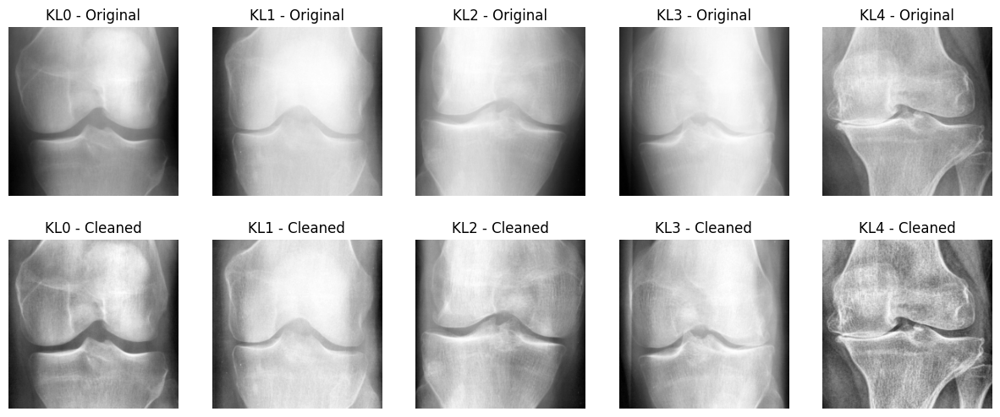

In [19]:
import matplotlib.pyplot as plt
from PIL import Image

fig, axes = plt.subplots(2, NUM_CLASSES, figsize=(3 * NUM_CLASSES, 6))
for k in range(NUM_CLASSES):
    path_k = train.samples[train.targets.index(k)][0]
    original = Image.open(path_k).convert("L")
    cleaned = Denoise()(original)
    axes[0][k].imshow(original, cmap="gray"); axes[0][k].set_title(f"{CLASS_NAMES[k]} - Original"); axes[0][k].axis("off")
    axes[1][k].imshow(cleaned, cmap="gray"); axes[1][k].set_title(f"{CLASS_NAMES[k]} - Cleaned"); axes[1][k].axis("off")
plt.show()

# مو مهم بس عشان اشوف الصور قبل وبعد

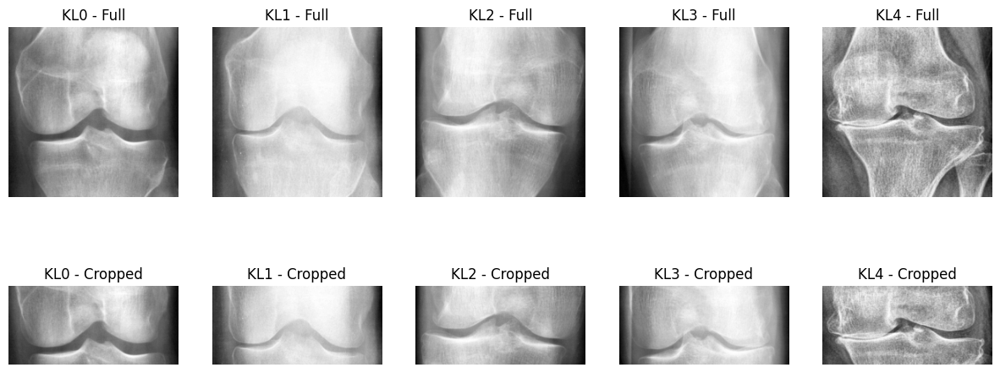

In [20]:
import matplotlib.pyplot as plt
from PIL import Image

def crop_center(img, top=60, bottom=60):
    img = img.resize((224, 224))
    return img.crop((0, top, 224, 224 - bottom))   # 224 x 104

fig, axes = plt.subplots(2, NUM_CLASSES, figsize=(3 * NUM_CLASSES, 6))
for k in range(NUM_CLASSES):
    p = train.samples[train.targets.index(k)][0]
    original = Denoise()(Image.open(p).convert("L")).resize((224, 224))
    cropped = crop_center(Denoise()(Image.open(p).convert("L")))
    axes[0][k].imshow(original, cmap="gray"); axes[0][k].set_title(f"{CLASS_NAMES[k]} - Full"); axes[0][k].axis("off")
    axes[1][k].imshow(cropped, cmap="gray"); axes[1][k].set_title(f"{CLASS_NAMES[k]} - Cropped"); axes[1][k].axis("off")
plt.show()


batch shape: torch.Size([32, 3, 104, 224])

Total images: 8260 | joint found: 7939 | fallback crop: 321
Joint far from the usual position (shift was clipped): 173
  Grade 0: joint not found in 58 of 3253 (2%)
  Grade 1: joint not found in 24 of 1495 (2%)
  Grade 2: joint not found in 78 of 2175 (4%)
  Grade 3: joint not found in 106 of 1086 (10%)
  Grade 4: joint not found in 55 of 251 (22%)
When the joint is found, the crop always covers rows 88 to 160


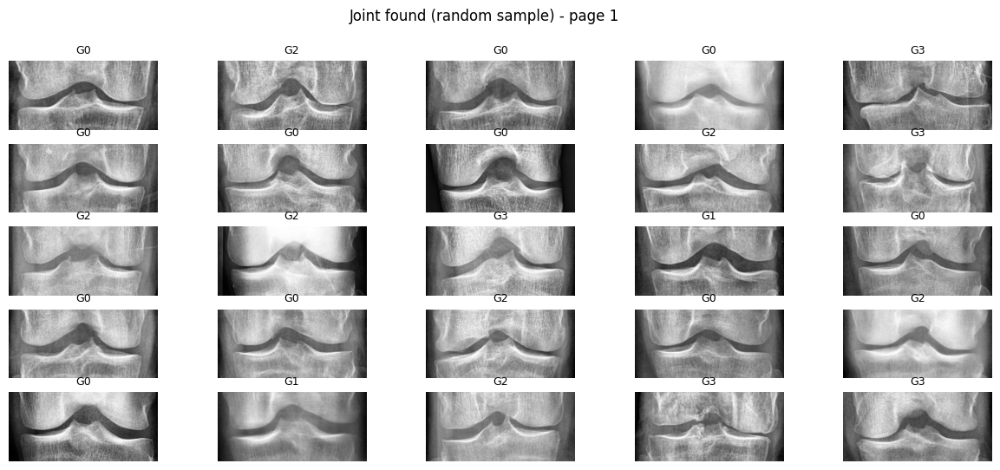

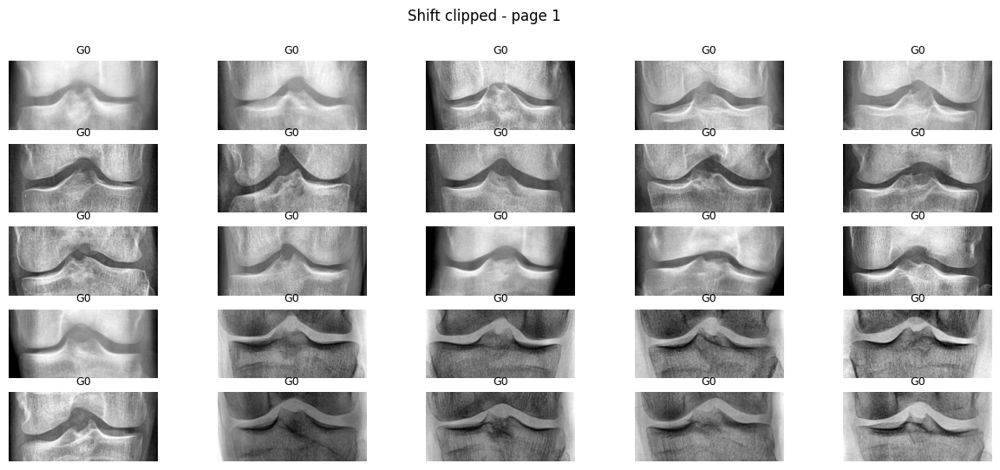

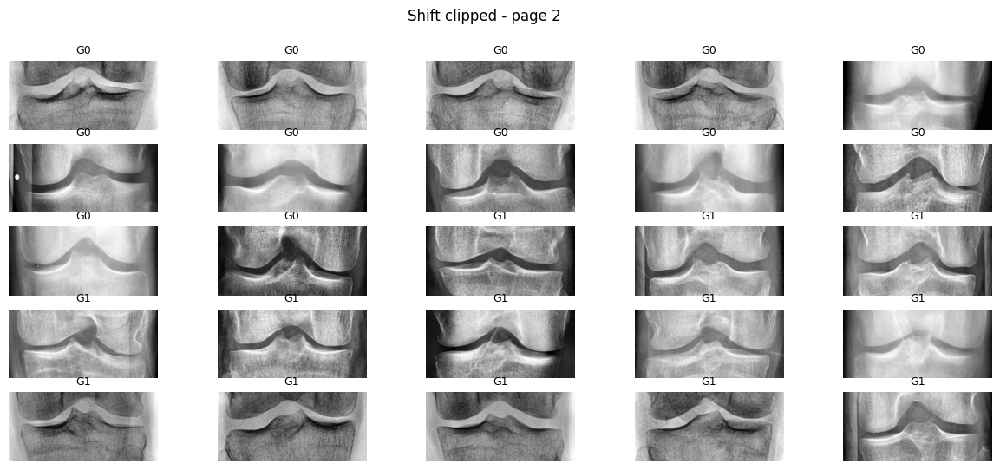

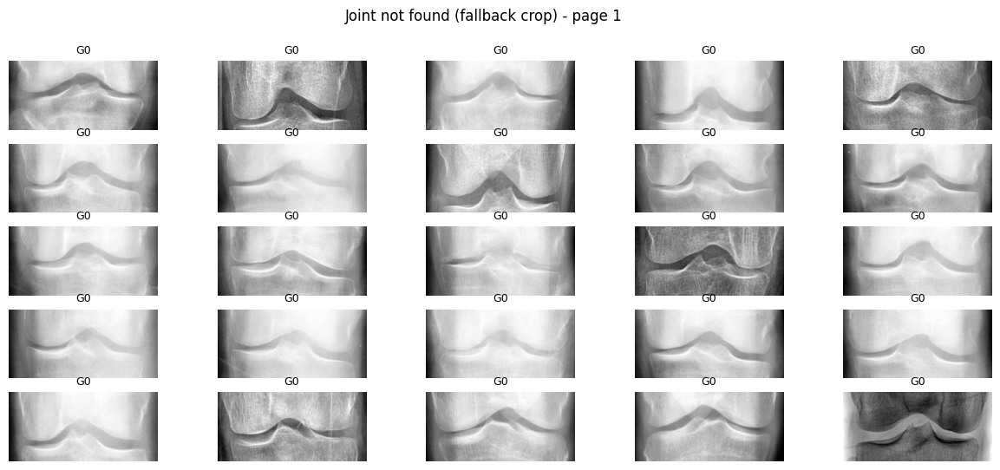

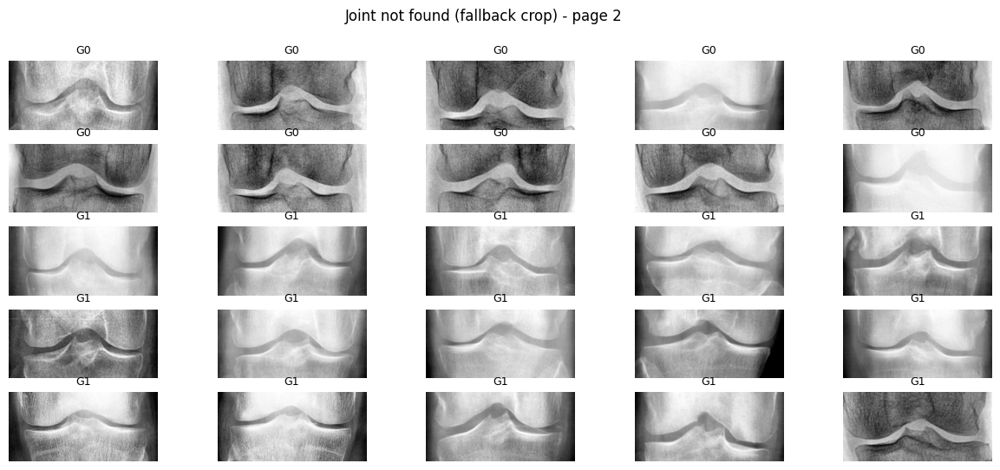

...

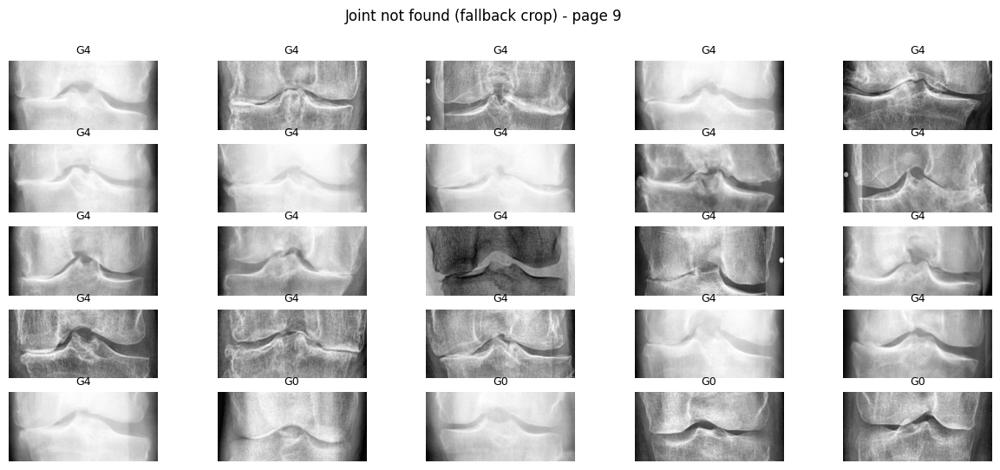

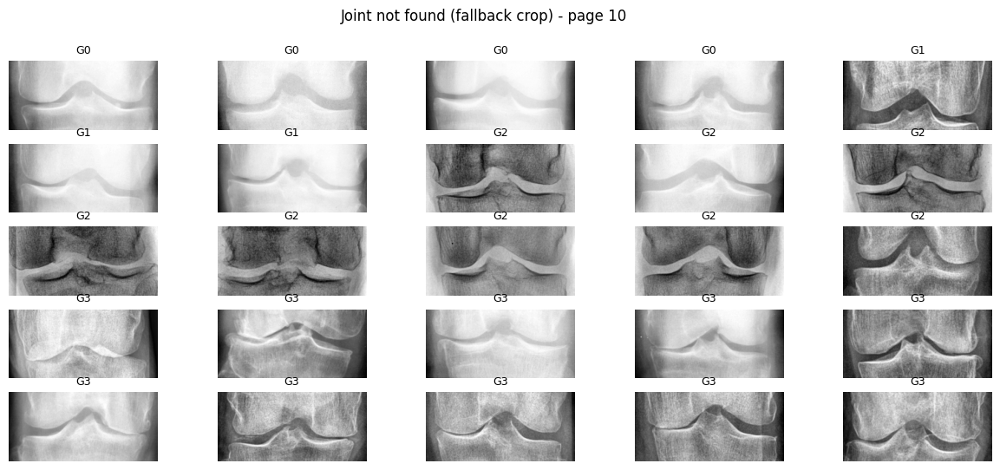

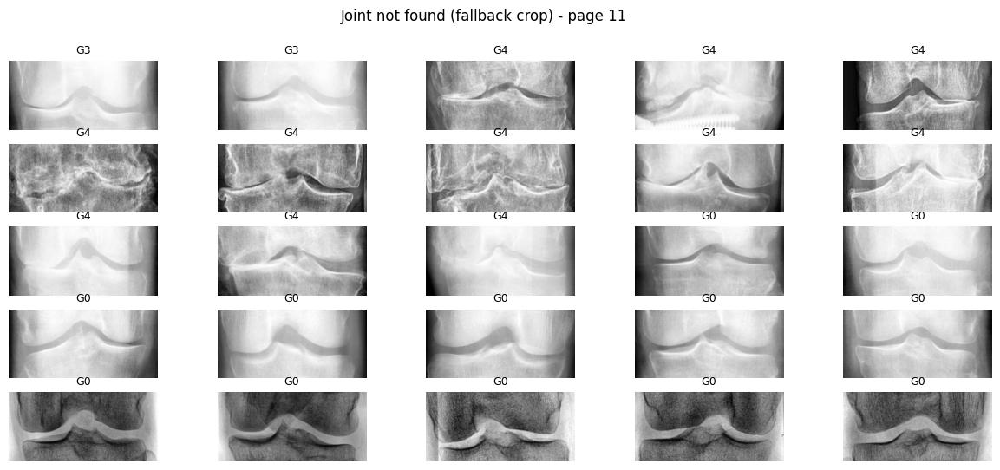

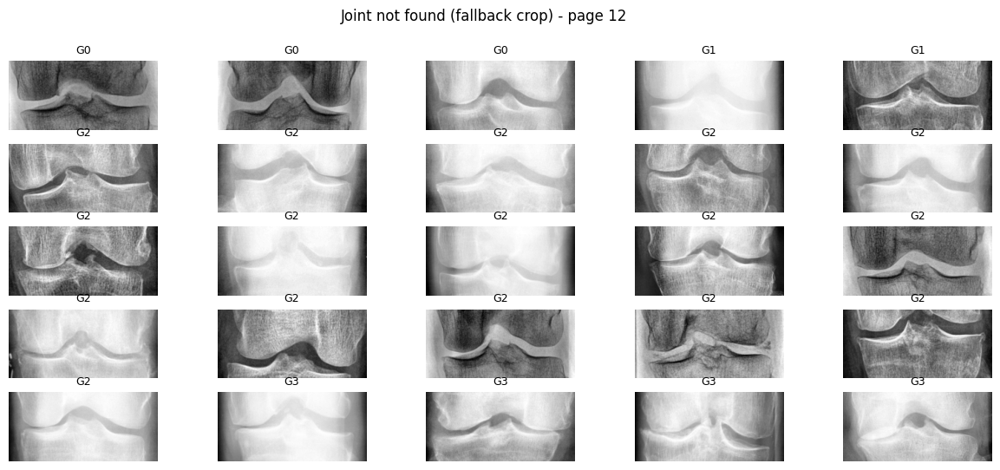

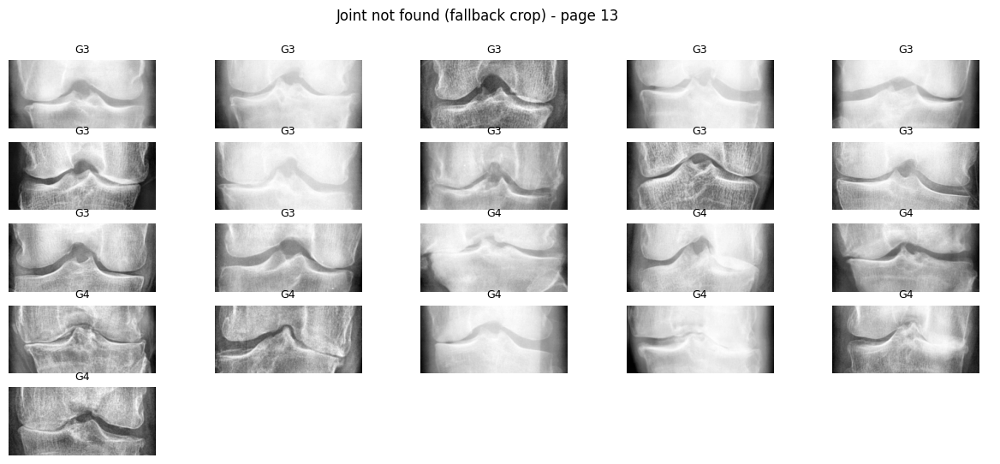

In [25]:
# ======================= NEW: joint-aware crop (single cell) =======================
# Run this AFTER the original cells (it needs `base` and the original `Denoise` class).
# Nothing from the original pipeline is changed: every new object ends with "_smart".
import random
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d
from scipy.signal import find_peaks

# ---------- Settings (change values here only) ----------
SIZE = 224
WINDOW_H = 104        # crop height (same as the 60/60 crop: 224 - 60 - 60)
PRIOR_ROW = 124       # most likely joint row (measured median 0.554 x 224)
MAX_SHIFT = 16        # max shift allowed from PRIOR_ROW (protects against a wrong detection)
FALLBACK_ROW = 124    # crop center when no joint is found (use 112 for the exact 60/60 crop)
RUN_CHECK = True      # True = scan all images and show examples, False = skip the check


# ---------- 1) Find the joint space ----------
def find_joint_row(gray, lo=0.40, hi=0.70, min_prom=4):
    """Return the row of the joint space, or None if it is not found."""
    H, W = gray.shape
    cols = gray[:, int(W * 0.25):int(W * 0.75)].astype(np.float32)   # central columns only
    prof = gaussian_filter1d(cols.mean(axis=1), sigma=H * 0.02)      # smoothed brightness of each row
    a, b = int(H * lo), int(H * hi)                                  # search only where the joint usually is
    peaks, props = find_peaks(-prof[a:b], prominence=min_prom)       # darkest valley = joint gap
    if len(peaks) == 0:
        return None
    return a + int(peaks[np.argmax(props["prominences"])])


# ---------- 2) Denoise + crop around the joint ----------
class SmartCrop:
    def __init__(self):
        self.denoise = Denoise()                                     # the original Denoise class (unchanged)
    def __call__(self, img):
        img = img.convert("L").resize((SIZE, SIZE))
        row = find_joint_row(np.array(img))                          # detect on the raw image
        if row is None:
            center = FALLBACK_ROW                                    # not found: crop around the most likely position
        else:                                                        # found: center on it, with a limited shift
            center = int(np.clip(row, PRIOR_ROW - MAX_SHIFT, PRIOR_ROW + MAX_SHIFT))
        top = center - WINDOW_H // 2
        return self.denoise(img).crop((0, top, SIZE, top + WINDOW_H))   # 224 x 104


# ---------- 3) Same pipeline as the original, but SmartCrop replaces Denoise + Resize ----------
# No Resize here: SmartCrop already returns the final 224 x 104 image.
tf_smart = transforms.Compose([                                      # val / test (no augmentation)
    SmartCrop(),
    transforms.Grayscale(3),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])
train_tf_smart = transforms.Compose([                                # train (with augmentation)
    SmartCrop(),
    transforms.Grayscale(3),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

train_smart = datasets.ImageFolder(f"{base}/train", transform=train_tf_smart)
val_smart   = datasets.ImageFolder(f"{base}/val",   transform=tf_smart)
test_smart  = datasets.ImageFolder(f"{base}/test",  transform=tf_smart)

train_loader_smart = DataLoader(train_smart, batch_size=32, shuffle=True,  num_workers=2)
val_loader_smart   = DataLoader(val_smart,   batch_size=32, shuffle=False, num_workers=2)
test_loader_smart  = DataLoader(test_smart,  batch_size=32, shuffle=False, num_workers=2)
print("batch shape:", next(iter(train_loader_smart))[0].shape)       # expected [32, 3, 104, 224]


# ---------- 4) Check (a bit slow; set RUN_CHECK = False once you are done) ----------
if RUN_CHECK:
    info = []                                        # (grade, joint row or None, image path)
    for ds in (train_smart, val_smart, test_smart):
        for p, g in ds.samples:
            gray = np.array(Image.open(p).convert("L").resize((SIZE, SIZE)))
            info.append((g, find_joint_row(gray), p))
    found = [x for x in info if x[1] is not None]
    fallback = [x for x in info if x[1] is None]
    clipped = [x for x in found if abs(x[1] - PRIOR_ROW) > MAX_SHIFT]

    print(f"\nTotal images: {len(info)} | joint found: {len(found)} | fallback crop: {len(fallback)}")
    print(f"Joint far from the usual position (shift was clipped): {len(clipped)}")
    for k in range(5):
        n = sum(1 for x in info if x[0] == k)
        f = sum(1 for x in fallback if x[0] == k)
        print(f"  Grade {k}: joint not found in {f} of {n} ({100 * f / n:.0f}%)")
    lo_c = PRIOR_ROW + MAX_SHIFT - WINDOW_H // 2
    hi_c = PRIOR_ROW - MAX_SHIFT + WINDOW_H // 2
    print(f"When the joint is found, the crop always covers rows {lo_c} to {hi_c}")

    sc = SmartCrop()
    def show_pages(items, title, max_pages=20):
        for pg in range(min(max_pages, -(-len(items) // 25))):
            fig, axes = plt.subplots(5, 5, figsize=(15, 6))
            for ax in axes.ravel(): ax.axis("off")
            for ax, x in zip(axes.ravel(), items[pg * 25:(pg + 1) * 25]):
                ax.imshow(sc(Image.open(x[2])), cmap="gray")         # same image the model sees
                ax.set_title(f"G{x[0]}", fontsize=9)
            fig.suptitle(f"{title} - page {pg + 1}")
            plt.show()

    random.seed(1)
    show_pages(random.sample(found, 25), "Joint found (random sample)", 1)
    show_pages(clipped, "Shift clipped", 2)
    show_pages(fallback, "Joint not found (fallback crop)")


train | ok 5758 | fallback 2 | off_center 18
val   | ok 819 | fallback 0 | off_center 7
test  | ok 1651 | fallback 1 | off_center 4


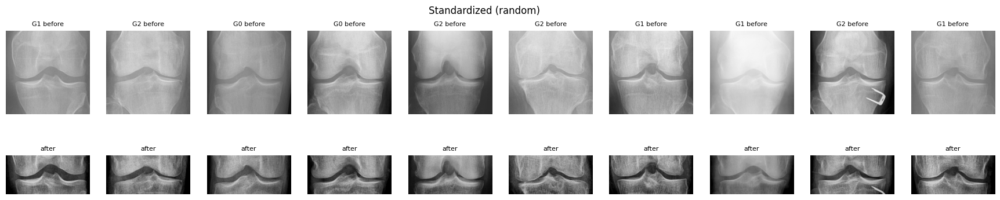

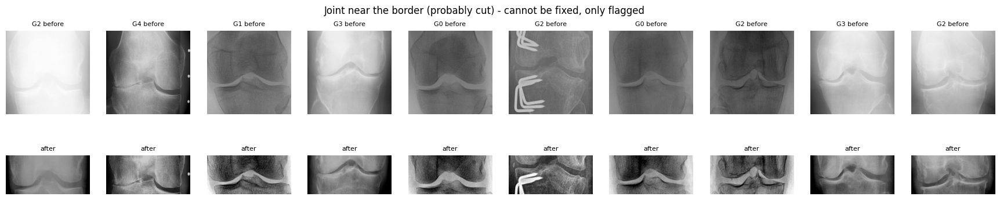

Mean-brightness std over 300 images: before 28.8 -> after 4.0


In [26]:
# ============ NEW (separate cell, run after the original cells) ============
# Image standardization: same brightness/contrast + joint centered + flag images with a cut joint.
# Nothing existing is changed. All new names end with "_std".
import cv2, numpy as np
from PIL import Image
from scipy.ndimage import gaussian_filter1d
from scipy.signal import find_peaks
import matplotlib.pyplot as plt

# ---------- Settings ----------
SIZE_STD = 224
WINDOW_H_STD = 104         # output = 224 x 104
TARGET_MEAN, TARGET_STD = 110.0, 55.0   # every image is forced to this brightness / contrast

MIN_CONTRAST = 4                        # weak valley = joint not clear


def joint_row_std(gray, lo=0.40, hi=0.70, min_prom=MIN_CONTRAST):
    """Row of the joint gap (darkest valley in the central columns) or None."""
    H, W = gray.shape
    prof = gaussian_filter1d(gray[:, int(W*.25):int(W*.75)].astype(np.float32).mean(1), sigma=H*0.02)
    a, b = int(H*lo), int(H*hi)
    pk, pr = find_peaks(-prof[a:b], prominence=min_prom)
    return None if len(pk) == 0 else a + int(pk[np.argmax(pr["prominences"])])


def standardize_std(img):
    """PIL image -> (standardized PIL image 224x104, status). status: ok / fallback / off_center."""
    g = np.array(img.convert("L").resize((SIZE_STD, SIZE_STD)))

    # 1) brightness / contrast: stretch 1-99 percentile, CLAHE, then fixed mean/std
    p1, p99 = np.percentile(g, (1, 99))
    g = np.clip((g.astype(np.float32) - p1) / max(p99 - p1, 1) * 255, 0, 255).astype(np.uint8)
    g = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(g)
    f = g.astype(np.float32)
    f = (f - f.mean()) / max(f.std(), 1e-3) * TARGET_STD + TARGET_MEAN
    g = np.clip(f, 0, 255).astype(np.uint8)

    # 2) joint-centered crop (detect on the standardized image)
    row = joint_row_std(g)
    status = "ok"
    if row is None:
        # not found in the usual band (40-70% of the height): look in a much wider band.
        # If a clear valley exists there, the joint is far from the usual place (near the border / probably cut).
        wide = joint_row_std(g, lo=0.10, hi=0.90)
        status = "off_center" if wide is not None else "fallback"
        row = 124                                           # crop around the most likely position
    row = int(np.clip(row, 124 - 16, 124 + 16))
    top = row - WINDOW_H_STD // 2
    return Image.fromarray(g).crop((0, top, SIZE_STD, top + WINDOW_H_STD)), status


# ---------- Scan all images, count the problems, show examples ----------
def scan_std(ds, name):
    out = {"ok": [], "fallback": [], "off_center": []}
    for p, y in ds.samples:
        _, st = standardize_std(Image.open(p))
        out[st].append((p, y))
    print(f"{name:5s} | ok {len(out['ok'])} | fallback {len(out['fallback'])} | off_center {len(out['off_center'])}")
    return out

SCAN_STD = {n: scan_std(d, n) for n, d in [("train", train), ("val", val), ("test", test)]}

def show_std(items, title, n=10):
    fig, ax = plt.subplots(2, n, figsize=(2.2 * n, 4.2))
    for i, (p, y) in enumerate(items[:n]):
        im = Image.open(p).convert("L").resize((SIZE_STD, SIZE_STD))
        ax[0][i].imshow(im, cmap="gray", vmin=0, vmax=255); ax[0][i].set_title(f"G{y} before", fontsize=8)
        ax[1][i].imshow(standardize_std(im)[0], cmap="gray", vmin=0, vmax=255); ax[1][i].set_title("after", fontsize=8)
        ax[0][i].axis("off"); ax[1][i].axis("off")
    fig.suptitle(title); plt.show()

import random; random.seed(0)
show_std(random.sample(SCAN_STD["train"]["ok"], 10), "Standardized (random)")
if SCAN_STD["train"]["off_center"]:
    show_std(random.sample(SCAN_STD["train"]["off_center"], min(10, len(SCAN_STD["train"]["off_center"]))),
             "Joint near the border (probably cut) - cannot be fixed, only flagged")

# Brightness check: spread of mean brightness before vs after (smaller = more uniform)
b_before, b_after = [], []
for p, _ in random.sample(train.samples, 300):
    im = Image.open(p).convert("L").resize((SIZE_STD, SIZE_STD))
    b_before.append(np.array(im).mean()); b_after.append(np.array(standardize_std(im)[0]).mean())
print(f"Mean-brightness std over 300 images: before {np.std(b_before):.1f} -> after {np.std(b_after):.1f}")


  train: 2000/5778
  train: 4000/5778

Images checked: 8260  (train 5778 | val 826 | test 1656)

check                             images      %
[HARD] wrong_size                      0   0.0%
[HARD] brightness_off               2335  28.3%
[HARD] low_contrast                    0   0.0%
[HARD] joint_near_crop_edge            7   0.1%
[soft] saturated (added)            7096  85.9%
[soft] noisy_original                 14   0.2%
[soft] blurry                        166   2.0%
[soft] big_black_area                  0   0.0%
[soft] joint_not_found                 3   0.0%
[soft] joint_far_from_usual           29   0.4%
[soft] joint_at_border (cut?)          0   0.0%
[soft] joint_weak_in_crop             30   0.4%
clean (no flag at all)               742   9.0%

Brightness uniformity (std of mean brightness across images; smaller = more uniform):
  before standardization: 27.3   after: 3.6
Contrast (std of pixel values): spread across images before 14.4 | after 2.4
Pure black/white pixels

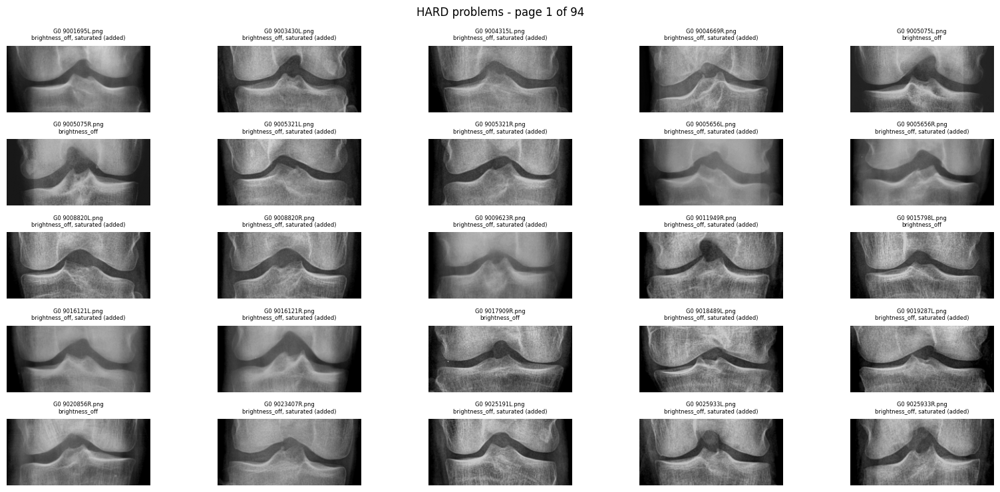

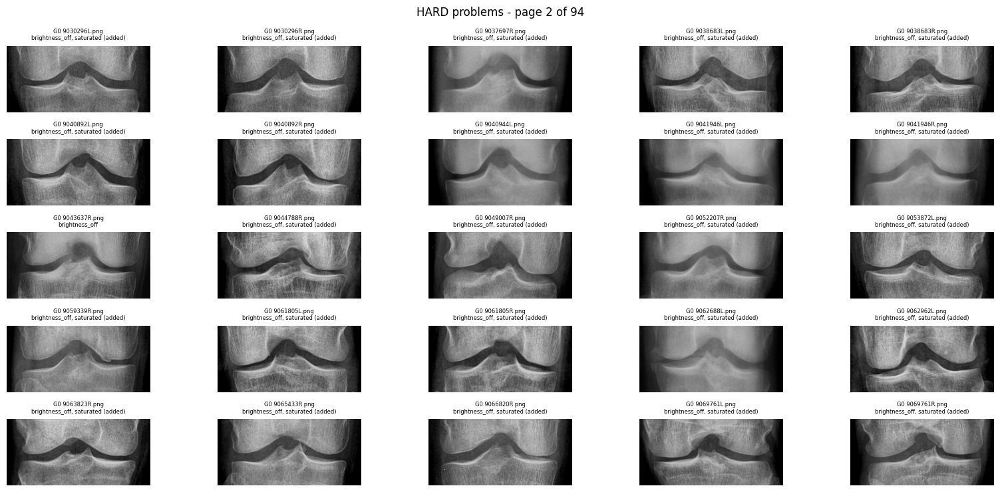

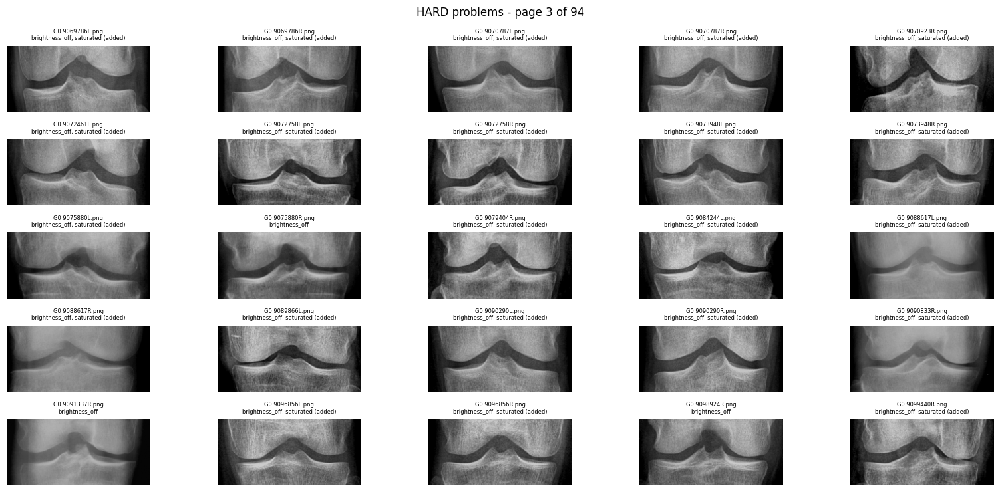

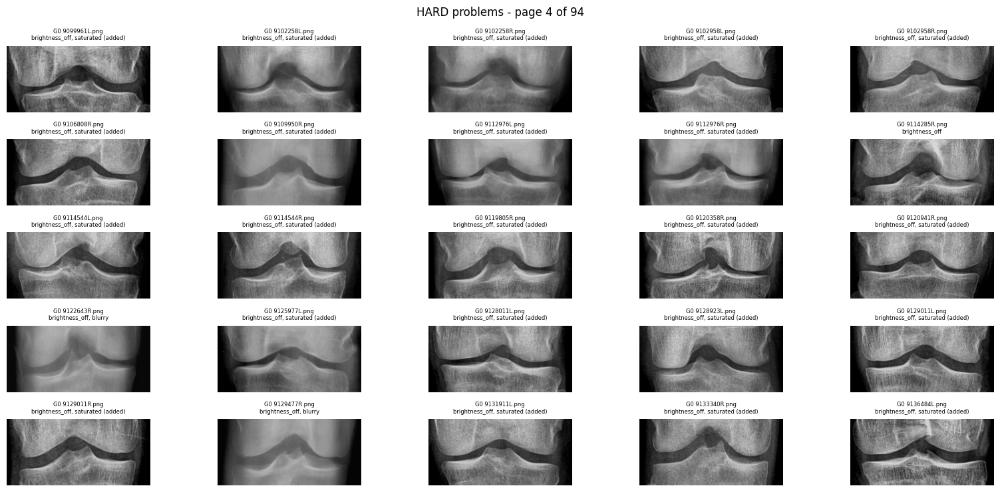

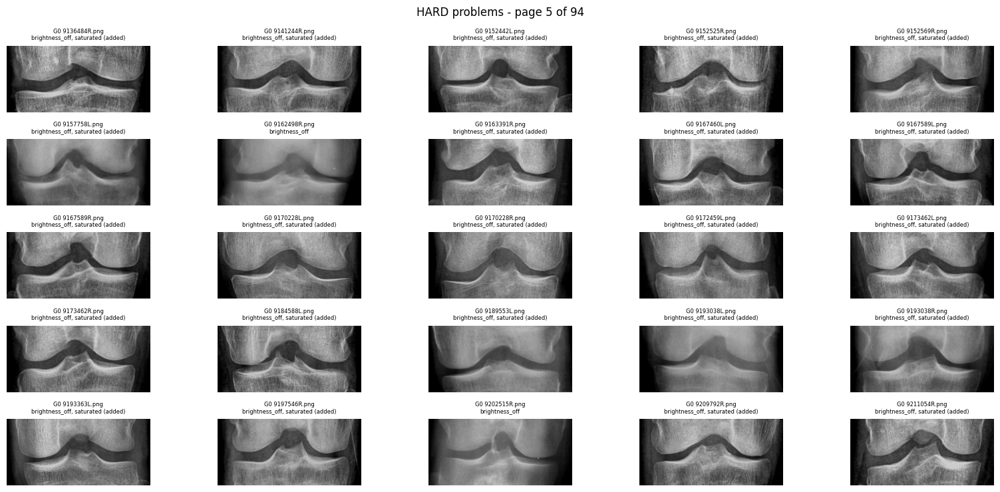

...

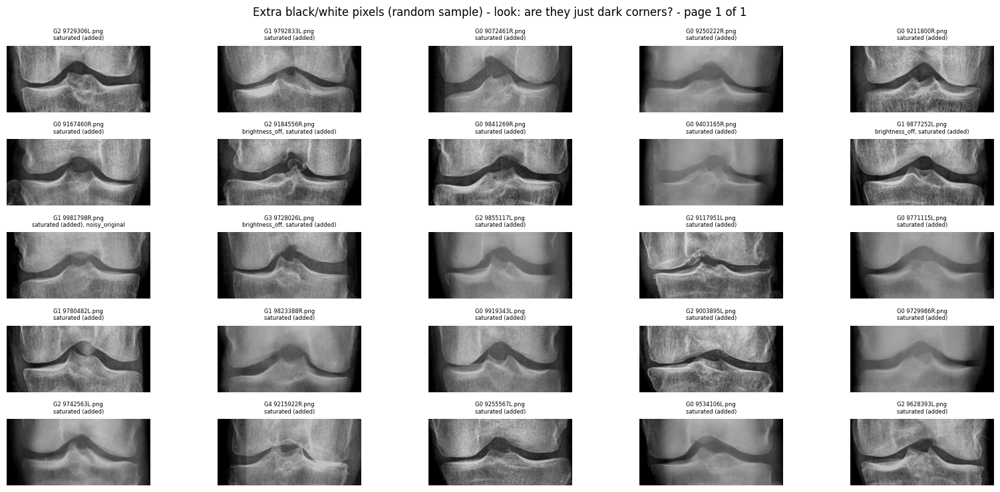

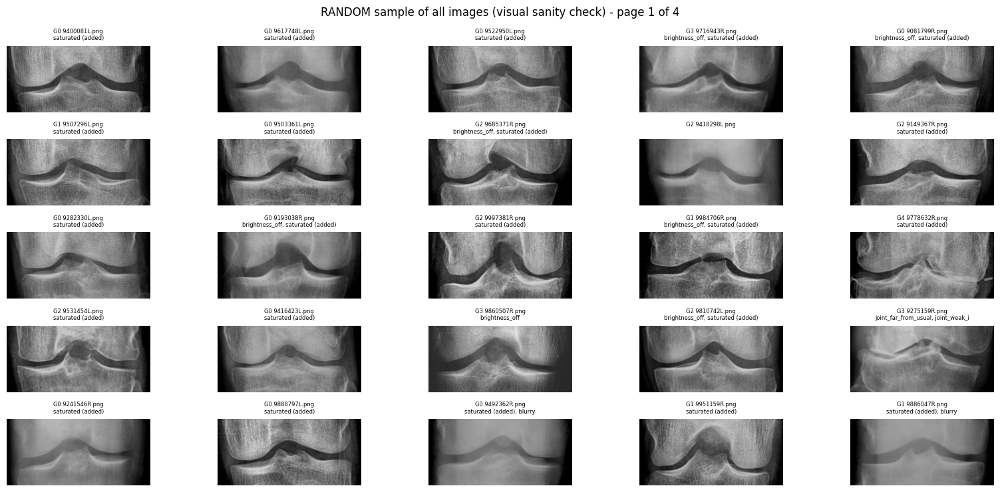

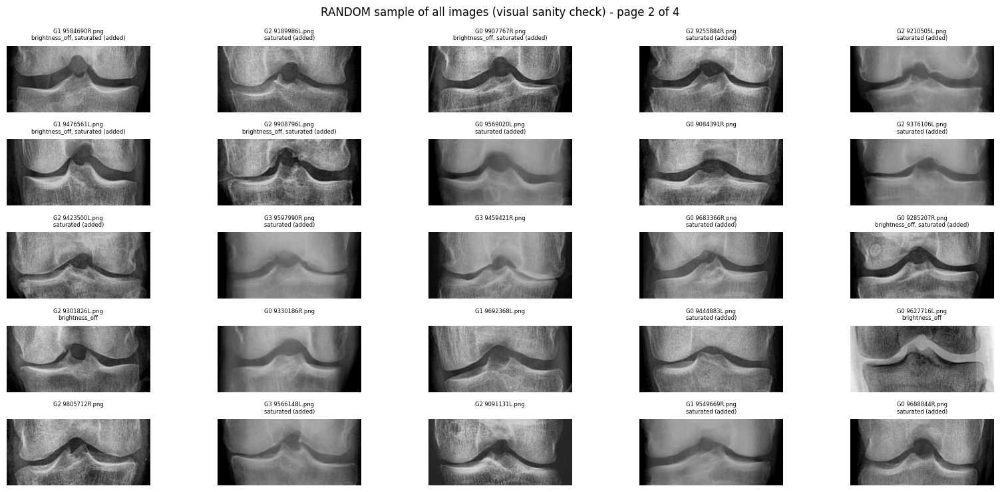

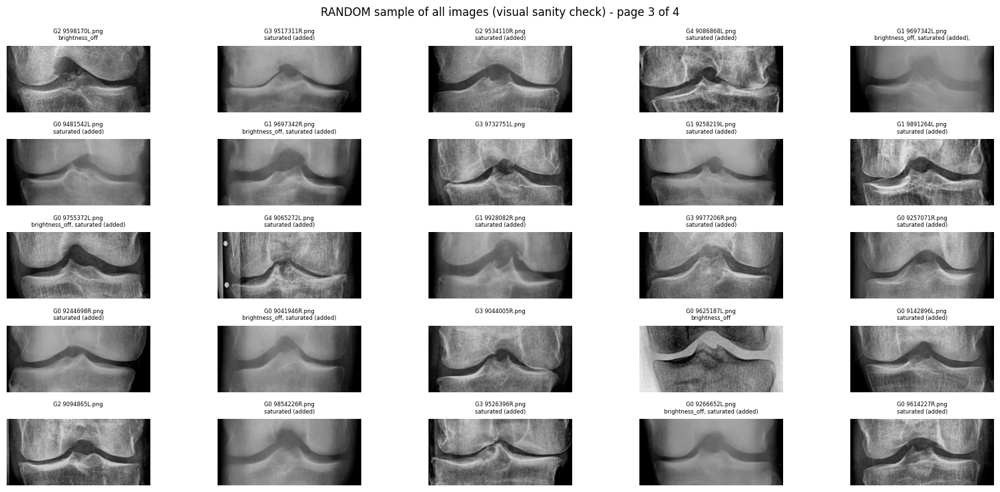

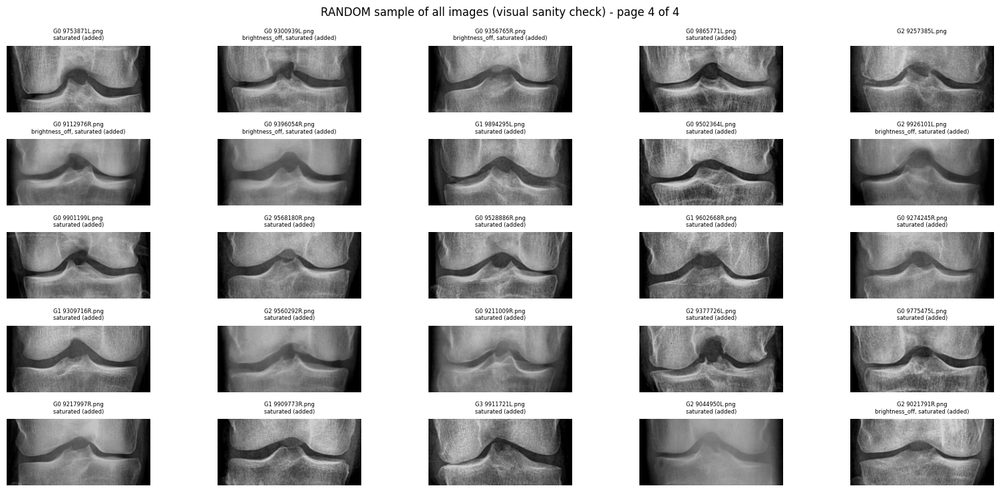


How to read this:
  - HARD must be 0 (or you looked at every image and accepted it).
  - soft flags are 'please look', not necessarily wrong. Train images you confirm are bad can be removed from TRAIN only.
  - never remove anything from val/test: the evaluation must stay on the full, untouched set.
  - details per image: standardized_check.csv


In [27]:
# ============ NEW (separate cell): full quality check of the standardized images ============
# Run AFTER the standardization cell (it needs standardize_std, SIZE_STD, WINDOW_H_STD, TARGET_MEAN).
# It measures the image the model will really see (after standardization + crop), for ALL images,
# writes standardized_check.csv and shows every suspicious image with its file name.
import random
import numpy as np, pandas as pd, cv2
import matplotlib.pyplot as plt
from PIL import Image
from scipy.ndimage import gaussian_filter1d
from scipy.signal import find_peaks

# ---------- Thresholds (change here only) ----------
MEAN_TOL      = 6      # output mean brightness must be within TARGET_MEAN +/- this
SAT_ADDED_MAX = 0.03   # max EXTRA fraction of pure black/white pixels created by the processing (natural black borders do not count)
RANGE_MIN     = 110    # min (p99 - p1) of the output = enough contrast
RAW_RANGE_MIN = 40     # original with less contrast than this = noise gets amplified
BLACK_MAX     = 0.25   # original with more than this fraction of black pixels (big empty border)
JOINT_PROM    = 8      # min depth of the joint-gap valley in the OUTPUT (brightness levels)
MARGIN_MIN    = 15     # joint must be at least this many pixels away from the top/bottom of the crop
BLUR_PCT      = 2      # sharpness below this percentile of the dataset = suspicious
MAX_PAGES     = 6      # pages shown per category (25 images per page)


def valley_in_crop(crop):
    """Joint gap inside the final crop: (row, depth) of the strongest dark valley, or (None, 0)."""
    H, W = crop.shape
    prof = gaussian_filter1d(crop[:, int(W * .25):int(W * .75)].astype(np.float32).mean(1), sigma=H * 0.03)
    pk, pr = find_peaks(-prof, prominence=1)                  # interior valleys only (an edge "valley" is not evidence of a joint)
    if len(pk) == 0:
        return None, 0.0
    i = int(np.argmax(pr["prominences"]))
    return int(pk[i]), float(pr["prominences"][i])


def check_one(path):
    im = Image.open(path)
    raw = np.array(im.convert("L").resize((SIZE_STD, SIZE_STD)))
    out_img, status = standardize_std(im)                      # exactly what the model gets
    out = np.array(out_img)
    H = out.shape[0]
    p1, p99 = np.percentile(out, (1, 99))
    r1, r99 = np.percentile(raw, (1, 99))
    row, depth = valley_in_crop(out)
    margin = -1 if row is None else min(row, H - row)
    return dict(
        path=path, status=status, orig_size=f"{im.size[0]}x{im.size[1]}",
        raw_mean=raw.mean(), raw_std=raw.std(), raw_range=r99 - r1, raw_black=(raw < 8).mean(),
        raw_sat=((raw == 0) | (raw == 255)).mean(),
        out_mean=out.mean(), out_std=out.std(), out_range=p99 - p1,
        out_sat=((out == 0) | (out == 255)).mean(),
        sharp=cv2.Laplacian(out, cv2.CV_64F).var(),
        joint_row=row, joint_depth=depth, joint_margin=margin, out_h=H,
    )


# ---------- 1) Measure every image ----------
rows = []
for split, ds in [("train", train), ("val", val), ("test", test)]:
    for k, (p, y) in enumerate(ds.samples):
        d = check_one(p); d.update(split=split, grade=y); rows.append(d)
        if (k + 1) % 2000 == 0:
            print(f"  {split}: {k + 1}/{len(ds.samples)}")
df = pd.DataFrame(rows)
sharp_cut = np.percentile(df["sharp"], BLUR_PCT)

# ---------- 2) Flags (one image can have several) ----------
FLAGS = {
    "wrong_size":     (df["out_h"] != WINDOW_H_STD) | (df["orig_size"] != f"{SIZE_STD}x{SIZE_STD}"),
    "brightness_off": (df["out_mean"] - TARGET_MEAN).abs() > MEAN_TOL,
    "saturated (added)": (df["out_sat"] - df["raw_sat"]) > SAT_ADDED_MAX,
    "low_contrast":   df["out_range"] < RANGE_MIN,
    "noisy_original": df["raw_range"] < RAW_RANGE_MIN,
    "blurry":         df["sharp"] < sharp_cut,
    "big_black_area": df["raw_black"] > BLACK_MAX,
    "joint_not_found": df["status"] == "fallback",
    "joint_far_from_usual":   df["status"] == "off_center",
    "joint_at_border (cut?)":    df["status"] == "edge",
    "joint_weak_in_crop": df["joint_depth"] < JOINT_PROM,
    "joint_near_crop_edge": (df["joint_margin"] >= 0) & (df["joint_margin"] < MARGIN_MIN),
}
for k, v in FLAGS.items():
    df[k] = v
HARD = ["wrong_size", "brightness_off", "low_contrast", "joint_near_crop_edge"]   # "saturated (added)" is soft: CLAHE + the 1% stretch create some white/black pixels by design
SOFT = [k for k in FLAGS if k not in HARD]
df["n_flags"] = df[list(FLAGS)].sum(axis=1)
df["reasons"] = df[list(FLAGS)].apply(lambda r: ", ".join(k for k in FLAGS if r[k]), axis=1)
df.drop(columns=list(FLAGS)).to_csv("standardized_check.csv", index=False)

# ---------- 3) Report ----------
N = len(df)
print(f"\nImages checked: {N}  (train {sum(df.split == 'train')} | val {sum(df.split == 'val')} | test {sum(df.split == 'test')})")
print(f"\n{'check':32s}{'images':>8s}{'%':>7s}")
for k in HARD + SOFT:
    n = int(df[k].sum()); print(f"{('[HARD] ' if k in HARD else '[soft] ') + k:32s}{n:8d}{100 * n / N:6.1f}%")
clean = int((df["n_flags"] == 0).sum())
print(f"{'clean (no flag at all)':32s}{clean:8d}{100 * clean / N:6.1f}%")

print("\nBrightness uniformity (std of mean brightness across images; smaller = more uniform):")
print(f"  before standardization: {df.raw_mean.std():.1f}   after: {df.out_mean.std():.1f}")
print(f"Contrast (std of pixel values): spread across images before {df.raw_std.std():.1f} | after {df.out_std.std():.1f}")
print(f"Pure black/white pixels: original {100 * df.raw_sat.mean():.1f}% of all pixels | after processing {100 * df.out_sat.mean():.1f}%")
print("\nMean brightness per grade (should be almost equal after; a gap would let the model cheat on brightness):")
print(df.groupby("grade")[["raw_mean", "out_mean"]].mean().round(1).to_string())
print("\nMean brightness per split (train / val / test must look the same):")
print(df.groupby("split")[["out_mean", "out_std", "sharp"]].mean().round(1).to_string())
print("\nJoint position inside the crop (rows 0-%d, centre = %d):" % (WINDOW_H_STD, WINDOW_H_STD // 2))
j = df[df.joint_row.notna()]
print(f"  median {j.joint_row.median():.0f} | 5th-95th percentile {j.joint_row.quantile(.05):.0f}-{j.joint_row.quantile(.95):.0f}")

# ---------- 4) Look at the suspicious images (file names in the titles) ----------
def show(items, title, max_pages=MAX_PAGES):
    items = list(items)
    for pg in range(min(max_pages, -(-len(items) // 25))):
        fig, axes = plt.subplots(5, 5, figsize=(16, 7.5))
        for ax in axes.ravel(): ax.axis("off")
        for ax, (_, r) in zip(axes.ravel(), items[pg * 25:(pg + 1) * 25]):
            ax.imshow(standardize_std(Image.open(r.path))[0], cmap="gray", vmin=0, vmax=255)
            ax.set_title(f"G{r.grade} {r.path.split('/')[-1][:18]}\n{r.reasons[:34]}", fontsize=6)
        fig.suptitle(f"{title} - page {pg + 1} of {-(-len(items) // 25)}")
        plt.tight_layout(); plt.show()

hard_any = df[df[HARD].any(axis=1)]
print(f"\nImages with at least one HARD problem: {len(hard_any)}")
if len(hard_any): show(hard_any.iterrows(), "HARD problems")
far = df[df["joint_far_from_usual"]]
if len(far): show(far.iterrows(), "Joint-like valley far from the usual place (crop kept at the usual position)")
cut = df[df["joint_at_border (cut?)"]]
if len(cut): show(cut.iterrows(), "Joint at the border (probably cut in the original)")
weak = df[df["joint_weak_in_crop"] & ~df["joint_at_border (cut?)"] & ~df["joint_far_from_usual"] & ~df["joint_not_found"]]
if len(weak): show(weak.iterrows(), "Joint gap weak/invisible inside the crop", 3)
nf = df[df["joint_not_found"]]
if len(nf): show(nf.iterrows(), "Joint not found (fallback crop)", 2)
random.seed(0)
sat_added = df[df["saturated (added)"]]
if len(sat_added): show(sat_added.sample(min(25, len(sat_added)), random_state=0).iterrows(), "Extra black/white pixels (random sample) - look: are they just dark corners?", 1)
# 100 random images of ALL images (not only the "clean" ones): if you look at them all and see no problem,
# the share of bad images is below about 3% (95% confidence, "rule of three")
show(df.sample(min(100, len(df)), random_state=1).iterrows(), "RANDOM sample of all images (visual sanity check)", 4)

print("\nHow to read this:")
print("  - HARD must be 0 (or you looked at every image and accepted it).")
print("  - soft flags are 'please look', not necessarily wrong. Train images you confirm are bad can be removed from TRAIN only.")
print("  - never remove anything from val/test: the evaluation must stay on the full, untouched set.")
print("  - details per image: standardized_check.csv")


  train: 2000/5778
  train: 4000/5778

Images checked: 8260  (train 5778 | val 826 | test 1656)

check                             images      %
[HARD] wrong_size                      0   0.0%
[HARD] brightness_off               2335  28.3%
[HARD] saturated (added)            7096  85.9%
[HARD] low_contrast                    0   0.0%
[HARD] joint_near_crop_edge         1404  17.0%
[soft] noisy_original                 14   0.2%
[soft] blurry                        166   2.0%
[soft] big_black_area                  0   0.0%
[soft] joint_not_found                 3   0.0%
[soft] joint_far_from_usual           29   0.4%
[soft] joint_at_border (cut?)          0   0.0%
[soft] joint_weak_in_crop              0   0.0%
clean (no flag at all)               445   5.4%

Brightness uniformity (std of mean brightness across images; smaller = more uniform):
  before standardization: 27.3   after: 3.6
Contrast (std of pixel values): spread across images before 14.4 | after 2.4
Pure black/white pixels

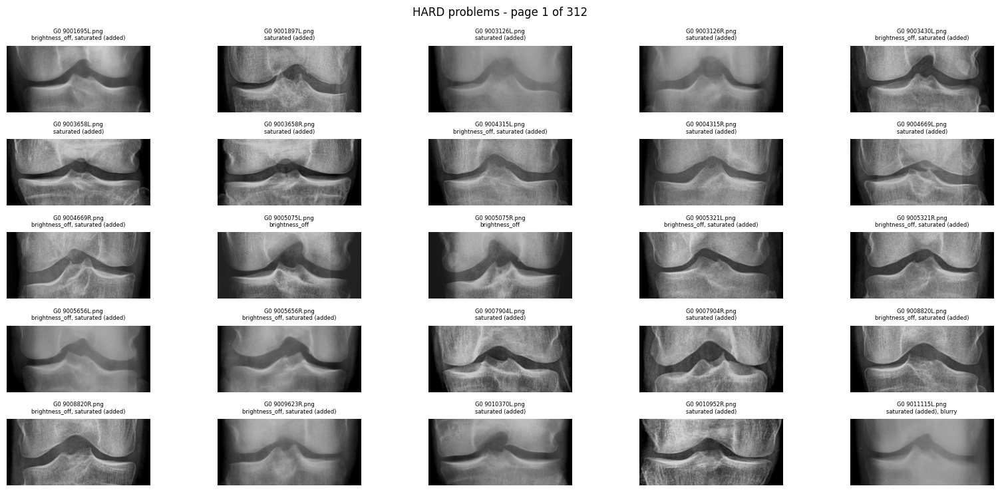

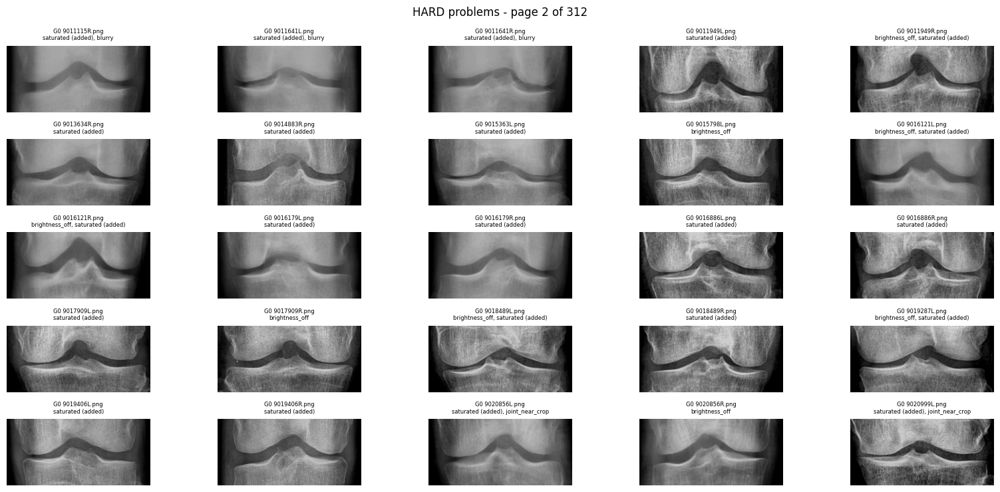

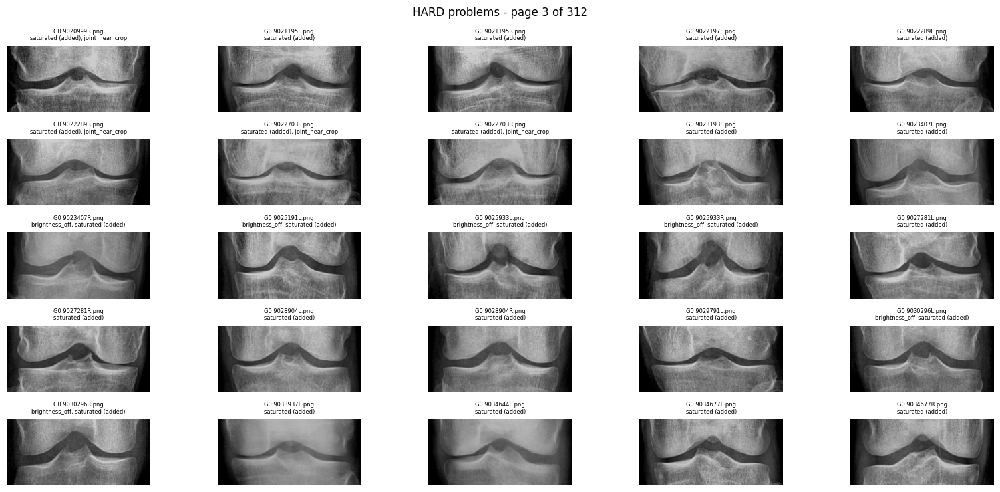

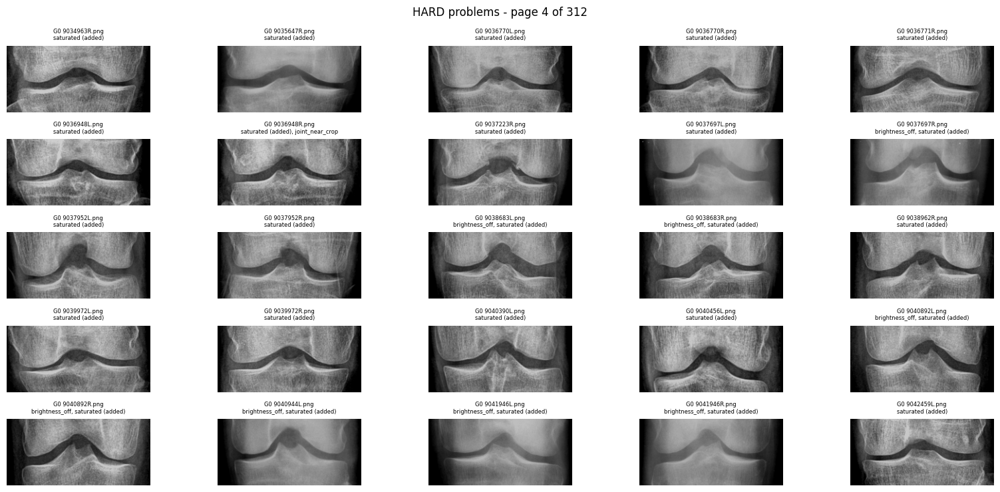

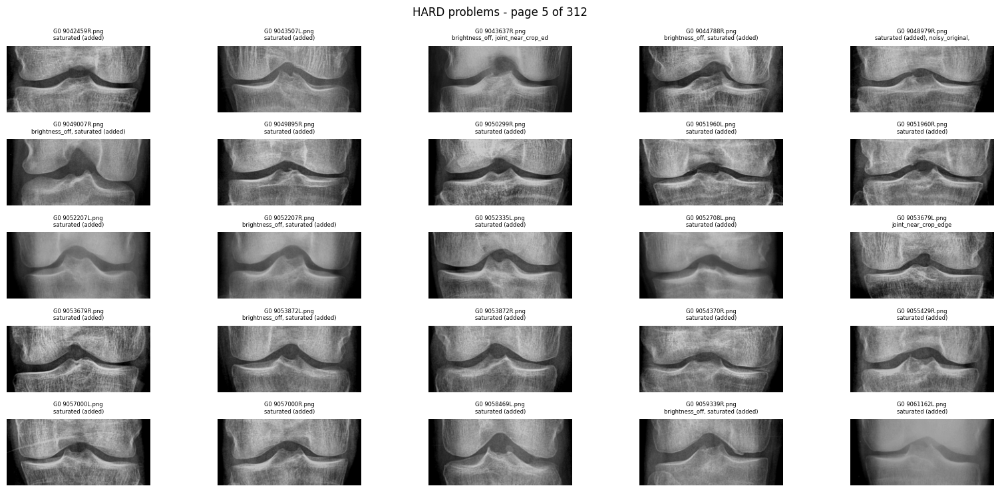

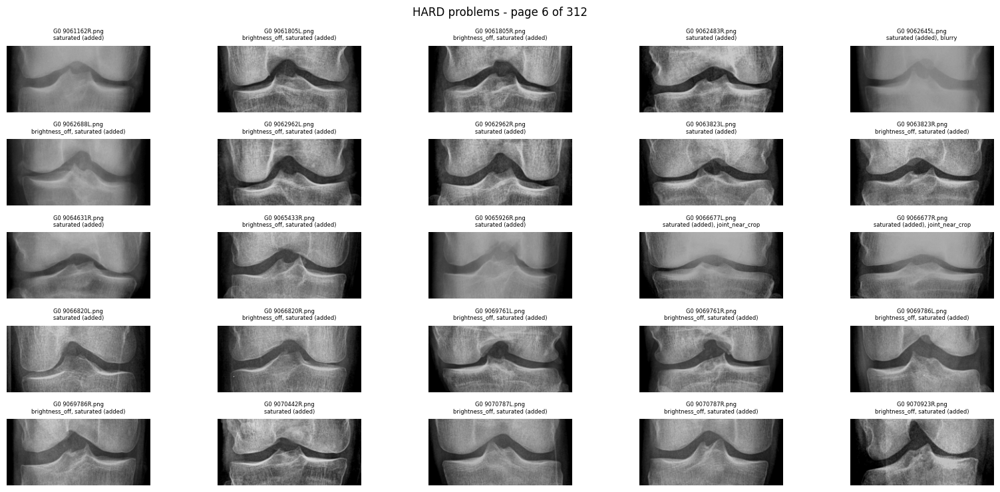

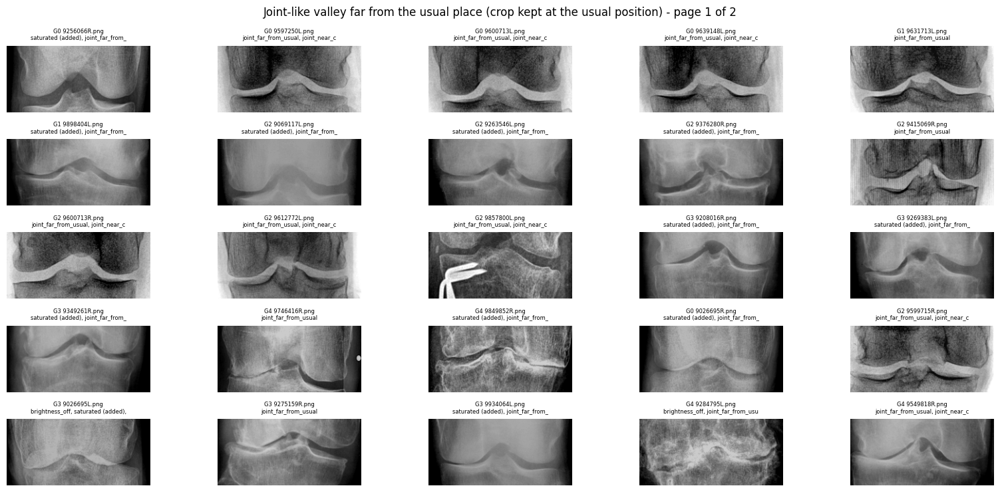

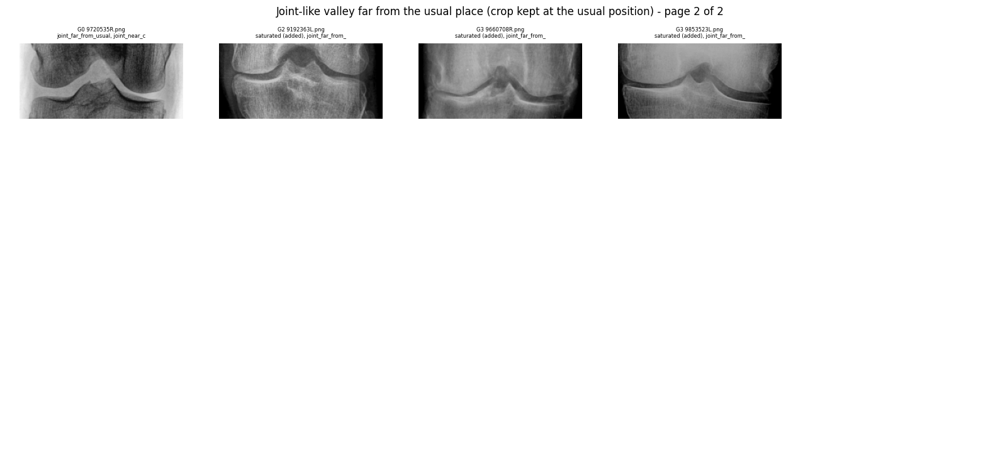

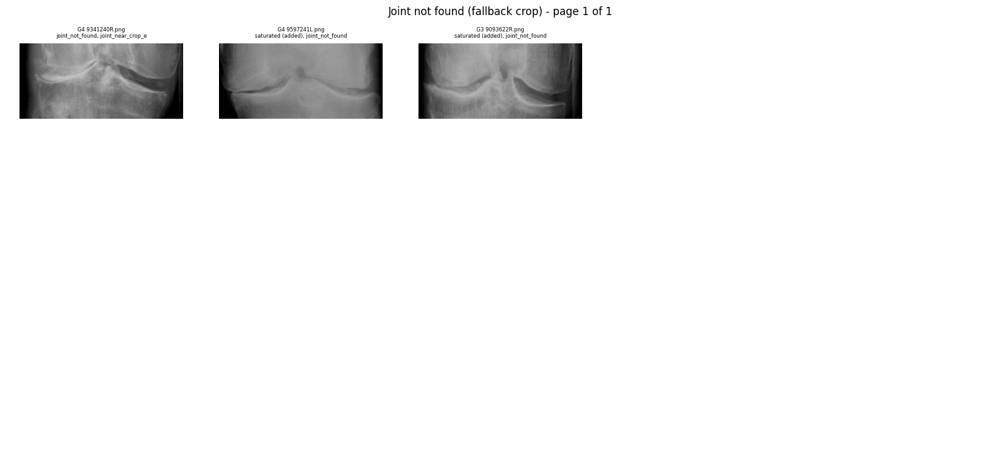

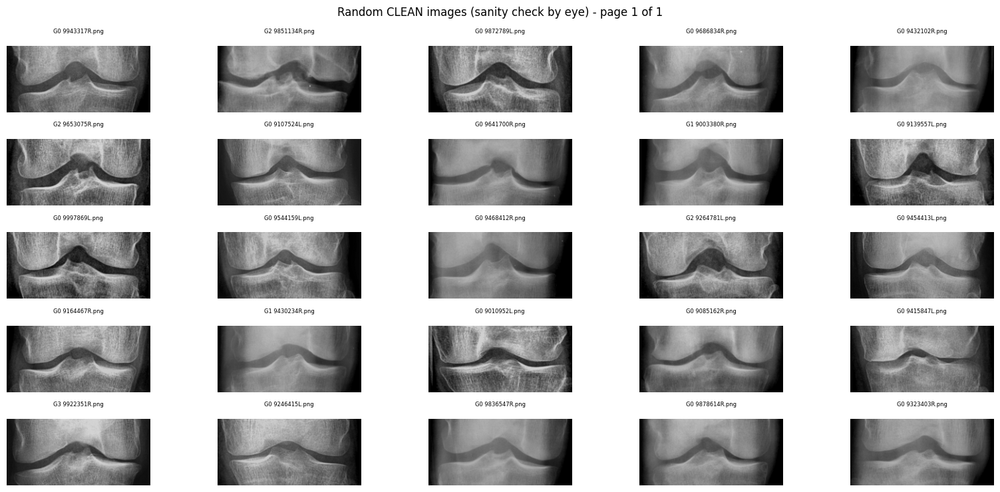


How to read this:
  - HARD must be 0 (or you looked at every image and accepted it).
  - soft flags are 'please look', not necessarily wrong. Train images you confirm are bad can be removed from TRAIN only.
  - never remove anything from val/test: the evaluation must stay on the full, untouched set.
  - details per image: standardized_check.csv


In [28]:
# ============ NEW (separate cell): full quality check of the standardized images ============
# Run AFTER the standardization cell (it needs standardize_std, SIZE_STD, WINDOW_H_STD, TARGET_MEAN).
# It measures the image the model will really see (after standardization + crop), for ALL images,
# writes standardized_check.csv and shows every suspicious image with its file name.
import random
import numpy as np, pandas as pd, cv2
import matplotlib.pyplot as plt
from PIL import Image
from scipy.ndimage import gaussian_filter1d
from scipy.signal import find_peaks

# ---------- Thresholds (change here only) ----------
MEAN_TOL      = 6      # output mean brightness must be within TARGET_MEAN +/- this
SAT_ADDED_MAX = 0.03   # max EXTRA fraction of pure black/white pixels created by the processing (natural black borders do not count)
RANGE_MIN     = 110    # min (p99 - p1) of the output = enough contrast
RAW_RANGE_MIN = 40     # original with less contrast than this = noise gets amplified
BLACK_MAX     = 0.25   # original with more than this fraction of black pixels (big empty border)
JOINT_PROM    = 8      # min depth of the joint-gap valley in the OUTPUT (brightness levels)
MARGIN_MIN    = 15     # joint must be at least this many pixels away from the top/bottom of the crop
BLUR_PCT      = 2      # sharpness below this percentile of the dataset = suspicious
MAX_PAGES     = 6      # pages shown per category (25 images per page)


def valley_in_crop(crop):
    """Joint gap inside the final crop: (row, depth) of the strongest dark valley, or (None, 0)."""
    H, W = crop.shape
    prof = gaussian_filter1d(crop[:, int(W * .25):int(W * .75)].astype(np.float32).mean(1), sigma=H * 0.03)
    pad = np.pad(prof, 1, constant_values=prof.max() + 1)     # lets a valley sitting AT the crop edge be found too
    pk, pr = find_peaks(-pad, prominence=1)
    if len(pk) == 0:
        return None, 0.0
    i = int(np.argmax(pr["prominences"]))
    return int(pk[i]) - 1, float(pr["prominences"][i])


def check_one(path):
    im = Image.open(path)
    raw = np.array(im.convert("L").resize((SIZE_STD, SIZE_STD)))
    out_img, status = standardize_std(im)                      # exactly what the model gets
    out = np.array(out_img)
    H = out.shape[0]
    p1, p99 = np.percentile(out, (1, 99))
    r1, r99 = np.percentile(raw, (1, 99))
    row, depth = valley_in_crop(out)
    margin = -1 if row is None else min(row, H - row)
    return dict(
        path=path, status=status, orig_size=f"{im.size[0]}x{im.size[1]}",
        raw_mean=raw.mean(), raw_std=raw.std(), raw_range=r99 - r1, raw_black=(raw < 8).mean(),
        raw_sat=((raw == 0) | (raw == 255)).mean(),
        out_mean=out.mean(), out_std=out.std(), out_range=p99 - p1,
        out_sat=((out == 0) | (out == 255)).mean(),
        sharp=cv2.Laplacian(out, cv2.CV_64F).var(),
        joint_row=row, joint_depth=depth, joint_margin=margin, out_h=H,
    )


# ---------- 1) Measure every image ----------
rows = []
for split, ds in [("train", train), ("val", val), ("test", test)]:
    for k, (p, y) in enumerate(ds.samples):
        d = check_one(p); d.update(split=split, grade=y); rows.append(d)
        if (k + 1) % 2000 == 0:
            print(f"  {split}: {k + 1}/{len(ds.samples)}")
df = pd.DataFrame(rows)
sharp_cut = np.percentile(df["sharp"], BLUR_PCT)

# ---------- 2) Flags (one image can have several) ----------
FLAGS = {
    "wrong_size":     (df["out_h"] != WINDOW_H_STD) | (df["orig_size"] != f"{SIZE_STD}x{SIZE_STD}"),
    "brightness_off": (df["out_mean"] - TARGET_MEAN).abs() > MEAN_TOL,
    "saturated (added)": (df["out_sat"] - df["raw_sat"]) > SAT_ADDED_MAX,
    "low_contrast":   df["out_range"] < RANGE_MIN,
    "noisy_original": df["raw_range"] < RAW_RANGE_MIN,
    "blurry":         df["sharp"] < sharp_cut,
    "big_black_area": df["raw_black"] > BLACK_MAX,
    "joint_not_found": df["status"] == "fallback",
    "joint_far_from_usual":   df["status"] == "off_center",
    "joint_at_border (cut?)":    df["status"] == "edge",
    "joint_weak_in_crop": df["joint_depth"] < JOINT_PROM,
    "joint_near_crop_edge": (df["joint_margin"] >= 0) & (df["joint_margin"] < MARGIN_MIN),
}
for k, v in FLAGS.items():
    df[k] = v
HARD = ["wrong_size", "brightness_off", "saturated (added)", "low_contrast", "joint_near_crop_edge"]
SOFT = [k for k in FLAGS if k not in HARD]
df["n_flags"] = df[list(FLAGS)].sum(axis=1)
df["reasons"] = df[list(FLAGS)].apply(lambda r: ", ".join(k for k in FLAGS if r[k]), axis=1)
df.drop(columns=list(FLAGS)).to_csv("standardized_check.csv", index=False)

# ---------- 3) Report ----------
N = len(df)
print(f"\nImages checked: {N}  (train {sum(df.split == 'train')} | val {sum(df.split == 'val')} | test {sum(df.split == 'test')})")
print(f"\n{'check':32s}{'images':>8s}{'%':>7s}")
for k in HARD + SOFT:
    n = int(df[k].sum()); print(f"{('[HARD] ' if k in HARD else '[soft] ') + k:32s}{n:8d}{100 * n / N:6.1f}%")
clean = int((df["n_flags"] == 0).sum())
print(f"{'clean (no flag at all)':32s}{clean:8d}{100 * clean / N:6.1f}%")

print("\nBrightness uniformity (std of mean brightness across images; smaller = more uniform):")
print(f"  before standardization: {df.raw_mean.std():.1f}   after: {df.out_mean.std():.1f}")
print(f"Contrast (std of pixel values): spread across images before {df.raw_std.std():.1f} | after {df.out_std.std():.1f}")
print(f"Pure black/white pixels: original {100 * df.raw_sat.mean():.1f}% of all pixels | after processing {100 * df.out_sat.mean():.1f}%")
print("\nMean brightness per grade (should be almost equal after; a gap would let the model cheat on brightness):")
print(df.groupby("grade")[["raw_mean", "out_mean"]].mean().round(1).to_string())
print("\nMean brightness per split (train / val / test must look the same):")
print(df.groupby("split")[["out_mean", "out_std", "sharp"]].mean().round(1).to_string())
print("\nJoint position inside the crop (rows 0-%d, centre = %d):" % (WINDOW_H_STD, WINDOW_H_STD // 2))
j = df[df.joint_row.notna()]
print(f"  median {j.joint_row.median():.0f} | 5th-95th percentile {j.joint_row.quantile(.05):.0f}-{j.joint_row.quantile(.95):.0f}")

# ---------- 4) Look at the suspicious images (file names in the titles) ----------
def show(items, title, max_pages=MAX_PAGES):
    items = list(items)
    for pg in range(min(max_pages, -(-len(items) // 25))):
        fig, axes = plt.subplots(5, 5, figsize=(16, 7.5))
        for ax in axes.ravel(): ax.axis("off")
        for ax, (_, r) in zip(axes.ravel(), items[pg * 25:(pg + 1) * 25]):
            ax.imshow(standardize_std(Image.open(r.path))[0], cmap="gray", vmin=0, vmax=255)
            ax.set_title(f"G{r.grade} {r.path.split('/')[-1][:18]}\n{r.reasons[:34]}", fontsize=6)
        fig.suptitle(f"{title} - page {pg + 1} of {-(-len(items) // 25)}")
        plt.tight_layout(); plt.show()

hard_any = df[df[HARD].any(axis=1)]
print(f"\nImages with at least one HARD problem: {len(hard_any)}")
if len(hard_any): show(hard_any.iterrows(), "HARD problems")
far = df[df["joint_far_from_usual"]]
if len(far): show(far.iterrows(), "Joint-like valley far from the usual place (crop kept at the usual position)")
cut = df[df["joint_at_border (cut?)"]]
if len(cut): show(cut.iterrows(), "Joint at the border (probably cut in the original)")
weak = df[df["joint_weak_in_crop"] & ~df["joint_at_border (cut?)"] & ~df["joint_far_from_usual"] & ~df["joint_not_found"]]
if len(weak): show(weak.iterrows(), "Joint gap weak/invisible inside the crop", 3)
nf = df[df["joint_not_found"]]
if len(nf): show(nf.iterrows(), "Joint not found (fallback crop)", 2)
random.seed(0)
show(df[df.n_flags == 0].sample(25, random_state=0).iterrows(), "Random CLEAN images (sanity check by eye)", 1)

print("\nHow to read this:")
print("  - HARD must be 0 (or you looked at every image and accepted it).")
print("  - soft flags are 'please look', not necessarily wrong. Train images you confirm are bad can be removed from TRAIN only.")
print("  - never remove anything from val/test: the evaluation must stay on the full, untouched set.")
print("  - details per image: standardized_check.csv")


# Agnostic Code

In [29]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print("device:", device, "|", torch.cuda.get_device_name(0) if device == 'cuda' else "NO GPU")
if device != 'cuda':
    raise RuntimeError("GPU is OFF -> EfficientNet-B5 on CPU takes ~20+ minutes per epoch. "
                       "Runtime > Change runtime type > T4 GPU, then Runtime > Run all.")


device: cuda | Tesla T4


# Training the model (EfficientNet-B5)

## Training

In [30]:
def train_step(model,
               data_loader,
               loss_fn,
               optm,
               acc_fn,
               scheduler = None,
               device = device):

  train_loss, train_acc = 0.0, 0.0

  model.to(device)

  model.train() # set model to training mode

  # itera through data/ batches
  for input, label in data_loader:
    input, label = input.to(device), label.to(device)

    # 1. forward
    output = model(input)

    # 2. calculate the loss
    loss = loss_fn(output, label)
    train_loss += loss.item() * input.size(0)
    train_acc += acc_fn(y_true=label, y_pred=output.argmax(dim=1))

    # 3. optimizer zero grad
    optm.zero_grad()

    # 4. loss backward
    loss.backward()

    # 5. optimizer step
    optm.step() # to change the weights

    # 6. scheduler step
    if scheduler is not None:
      scheduler.step()

  train_loss /= len(data_loader)
  train_acc /= len(data_loader)
  print(f'Train loss: {train_loss:.4f}, Train acc: {train_acc:.4f}')

In [31]:
import torch.backends.cudnn as cudnn
cudnn.benchmark = True   # hey GPU find the most optimized way to run

In [32]:
from sklearn.metrics import f1_score

def val_macro_f1():
    model.eval()
    preds, labels = [], []
    with torch.no_grad():
        for x, y in val_loader:
            preds.extend(model(x.to(device)).argmax(1).cpu().numpy())
            labels.extend(y.numpy())
    return f1_score(labels, preds, average="macro")

In [33]:
# Calculate accuracy (a classification metric)
def accuracy_fn(y_true, y_pred):
    """Calculates accuracy between truth labels and predictions.

    Args:
        y_true (torch.Tensor): Truth labels for predictions.
        y_pred (torch.Tensor): Predictions to be compared to predictions.

    Returns:
        [torch.float]: Accuracy value between y_true and y_pred, e.g. 78.45
    """
    correct = torch.eq(y_true, y_pred).sum().item()
    acc = (correct / len(y_pred)) * 100
    return acc

In [34]:
from sklearn.metrics import f1_score
import time

# Mixed precision (AMP) -> less GPU memory + much faster on T4
use_amp = (device == 'cuda')
FROZEN_BLOCKS = 0   # number of early blocks of model.features kept frozen (set in Phase 2)
scaler = torch.amp.GradScaler('cuda', enabled=use_amp)

def run_epoch(loader, optimizer=None, freeze_backbone=False):
    """Train one epoch if optimizer is given, otherwise just evaluate.
    Returns (loss, acc%, macro-F1) - F1 is computed in the SAME pass (no 2nd val pass)."""
    training = optimizer is not None
    model.train(training)
    if training and freeze_backbone:
        model.features.eval()              # keep frozen part fully fixed (like Keras)
    elif training and FROZEN_BLOCKS:
        for blk in model.features[:FROZEN_BLOCKS]:
            blk.eval()                     # frozen early blocks: also freeze BatchNorm statistics

    total_loss, correct, n = 0.0, 0, 0
    all_p, all_y = [], []
    with torch.set_grad_enabled(training):
        for i, (x, y) in enumerate(loader):
            if training and i == 5:
                t_s = time.time()          # start timing after warm-up batches
            x = x.to(device, non_blocking=True, memory_format=torch.channels_last)
            y = y.to(device, non_blocking=True)
            with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=use_amp):
                out = model(x)
                loss = loss_fn(out, y)
            if training:
                optimizer.zero_grad(set_to_none=True)
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()
            if training and i == 25:
                ips = 20 * loader.batch_size / (time.time() - t_s)
                print(f"   speed: {ips:.0f} img/s -> about {len(loader.dataset) / ips / 60:.1f} min per training epoch")
            pred = out.argmax(1)
            total_loss += loss.item() * len(y)
            correct += (pred == y).sum().item()
            n += len(y)
            if not training:
                all_p.append(pred.cpu()); all_y.append(y.cpu())
    f1 = f1_score(torch.cat(all_y), torch.cat(all_p), average="macro") if not training else float('nan')
    return total_loss / n, 100 * correct / n, f1


In [35]:
def test_report():
    te_loss, te_acc, _ = run_epoch(test_loader)
    print(f"TEST loss {te_loss:.3f} | TEST acc {te_acc:.2f}%")
    model.eval()
    preds, labels = [], []
    with torch.no_grad(), torch.autocast(device_type='cuda', dtype=torch.float16, enabled=use_amp):
        for x, y in test_loader:
            x = x.to(device, memory_format=torch.channels_last)
            preds.extend(model(x).argmax(1).cpu().numpy())
            labels.extend(y.numpy())
    print(classification_report(labels, preds, zero_division=0))
    print(confusion_matrix(labels, preds))


In [36]:
import copy, time

def fit(optimizer, epochs, freeze_backbone, name, scheduler=None, patience=None):
    best_score, best_state, bad = 0, None, 0

    for e in range(epochs):
        t0 = time.time()
        tr_loss, tr_acc, _ = run_epoch(train_loader, optimizer, freeze_backbone)
        va_loss, va_acc, f1 = run_epoch(val_loader)      # one val pass gives loss, acc and F1
        if scheduler is not None:
            scheduler.step()

        if best_state is None or f1 > best_score:
            best_score, best_state, bad = f1, copy.deepcopy(model.state_dict()), 0
        else:
            bad += 1

        print(f"[{name}] Epoch {e+1:02d}/{epochs} | "
              f"train loss {tr_loss:.3f} acc {tr_acc:.1f} | "
              f"val loss {va_loss:.3f} acc {va_acc:.1f} | "
              f"val F1 {f1:.3f} | {time.time()-t0:.0f}s")

        if patience is not None and bad >= patience:
            print(f"Early stopping (no val-F1 improvement for {patience} epochs)")
            break

    model.load_state_dict(best_state)
    print(f"Restored best epoch (val F1 {best_score:.3f})")


## PHASE 1 -- freeze EfficientNet-B5, train only the new layer, 3 epochs

In [37]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import models
from sklearn.metrics import classification_report, confusion_matrix

# 1. Load the pre-trained EfficientNet-B5 model
model = models.efficientnet_b5(weights=models.EfficientNet_B5_Weights.DEFAULT)

# 2. Freeze all backbone parameters first
for param in model.parameters():
    param.requires_grad = False

# 3. Replace the final Linear layer (classifier = Dropout -> Linear).
#    Newly created layers have requires_grad=True by default.
num_ftrs = model.classifier[1].in_features      # 2048
model.classifier[1] = nn.Linear(num_ftrs, NUM_CLASSES)
model = model.to(device, memory_format=torch.channels_last)

# 4. Setup loss function and optimizer
# Pass only the classifier parameters to the optimizer for Phase 1
loss_fn = nn.CrossEntropyLoss(weight=class_weights.float().to(device), label_smoothing=0.1)
optm = optim.Adam(model.classifier.parameters(), lr=0.001)

acc_fn = accuracy_fn

# Run training Phase 1
fit(optm, epochs=3, freeze_backbone=True, name="Phase 1: frozen")

print("\n--- Test result after Phase 1 ---")
test_report()


Downloading: "https://download.pytorch.org/models/efficientnet_b5_lukemelas-1a07897c.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b5_lukemelas-1a07897c.pth


100%|██████████| 117M/117M [00:00<00:00, 178MB/s]


   speed: 216 img/s -> about 0.4 min per training epoch
[Phase 1: frozen] Epoch 01/3 | train loss 1.688 acc 27.6 | val loss 1.794 acc 32.9 | val F1 0.263 | 35s
   speed: 200 img/s -> about 0.5 min per training epoch
[Phase 1: frozen] Epoch 02/3 | train loss 1.628 acc 33.1 | val loss 1.779 acc 41.3 | val F1 0.357 | 23s
   speed: 302 img/s -> about 0.3 min per training epoch
[Phase 1: frozen] Epoch 03/3 | train loss 1.611 acc 34.3 | val loss 1.755 acc 44.2 | val F1 0.315 | 23s
Restored best epoch (val F1 0.357)

--- Test result after Phase 1 ---
TEST loss 1.786 | TEST acc 41.06%
              precision    recall  f1-score   support

           0       0.60      0.62      0.61       639
           1       0.18      0.23      0.20       296
           2       0.46      0.27      0.34       447
           3       0.44      0.28      0.34       223
           4       0.15      0.63      0.24        51

    accuracy                           0.41      1656
   macro avg       0.37      0.41   

## PHASE 2 -- fine-tune (early blocks frozen = faster), AdamW, warmup + cosine, early stopping

In [38]:
FROZEN_BLOCKS = 4     # stem + first 3 stages stay frozen (the slowest, high-resolution part). Set 0 to train everything.
EPOCHS2 = 20

for p in model.parameters():
    p.requires_grad = True
for blk in model.features[:FROZEN_BLOCKS]:
    for p in blk.parameters():
        p.requires_grad = False

# small LR for the pretrained backbone, bigger LR for the new head
optm = optim.AdamW([
    {"params": [p for p in model.features.parameters() if p.requires_grad], "lr": 5e-5},
    {"params": model.classifier.parameters(),                               "lr": 5e-4},
], weight_decay=1e-2)

# 2 epochs warmup, then cosine decay
warm  = optim.lr_scheduler.LinearLR(optm, start_factor=0.1, total_iters=2)
cos   = optim.lr_scheduler.CosineAnnealingLR(optm, T_max=EPOCHS2 - 2, eta_min=1e-6)
sched = optim.lr_scheduler.SequentialLR(optm, [warm, cos], milestones=[2])

fit(optm, epochs=EPOCHS2, freeze_backbone=False, name="Phase 2: fine-tune",
    scheduler=sched, patience=5)

print("\n--- Final test result after fine-tuning ---")
test_report()


   speed: 194 img/s -> about 0.5 min per training epoch
[Phase 2: fine-tune] Epoch 01/20 | train loss 1.756 acc 25.3 | val loss 1.817 acc 39.0 | val F1 0.330 | 58s
   speed: 193 img/s -> about 0.5 min per training epoch
[Phase 2: fine-tune] Epoch 02/20 | train loss 1.628 acc 32.1 | val loss 1.723 acc 49.5 | val F1 0.420 | 34s
   speed: 154 img/s -> about 0.6 min per training epoch
[Phase 2: fine-tune] Epoch 03/20 | train loss 1.481 acc 45.3 | val loss 1.626 acc 55.7 | val F1 0.529 | 35s
   speed: 186 img/s -> about 0.5 min per training epoch
[Phase 2: fine-tune] Epoch 04/20 | train loss 1.366 acc 52.5 | val loss 1.602 acc 55.9 | val F1 0.575 | 35s
   speed: 187 img/s -> about 0.5 min per training epoch
[Phase 2: fine-tune] Epoch 05/20 | train loss 1.286 acc 58.2 | val loss 1.577 acc 57.9 | val F1 0.609 | 34s
   speed: 151 img/s -> about 0.6 min per training epoch
[Phase 2: fine-tune] Epoch 06/20 | train loss 1.262 acc 59.7 | val loss 1.569 acc 59.0 | val F1 0.597 | 35s
   speed: 185 im

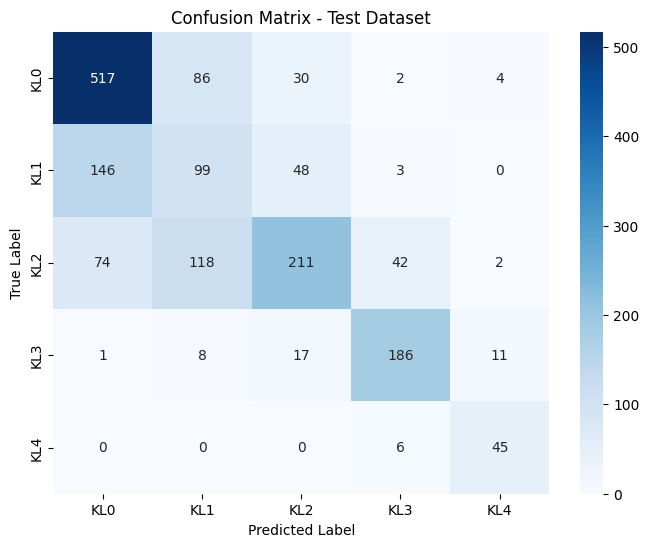

In [39]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Put model in evaluation mode
model.eval()
all_preds = []
all_labels = []

# Get predictions on test set
with torch.inference_mode():
    for inputs, labels in test_loader:
        inputs = inputs.to(device)
        outputs = model(inputs)
        preds = outputs.argmax(dim=1).cpu().numpy()

        all_preds.extend(preds)
        all_labels.extend(labels.numpy())

# Compute confusion matrix
cm = confusion_matrix(all_labels, all_preds)
class_names = train.classes

# Plot confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)
plt.title('Confusion Matrix - Test Dataset')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.show()

In [40]:
from sklearn.metrics import cohen_kappa_score
import torch

# Put model in evaluation mode
model.eval()
all_preds = []
all_labels = []

# Get predictions on the test set
with torch.inference_mode():
    for inputs, labels in test_loader:
        inputs = inputs.to(device)
        outputs = model(inputs)
        preds = outputs.argmax(dim=1).cpu().numpy()

        all_preds.extend(preds)
        all_labels.extend(labels.numpy())

# Calculate Quadratic Weighted Kappa (QWK)
qwk = cohen_kappa_score(all_labels, all_preds, weights='quadratic')
print(f"Quadratic Weighted Kappa (QWK): {qwk:.4f}")

Quadratic Weighted Kappa (QWK): 0.7884


## Final evaluation with TTA (original + horizontal flip) and QWK

In [41]:
from sklearn.metrics import cohen_kappa_score, classification_report, confusion_matrix

@torch.no_grad()
def predict_probs(loader, tta=True):
    model.eval()
    P, Y = [], []
    for x, y in loader:
        x = x.to(device, memory_format=torch.channels_last)
        with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=use_amp):
            p = model(x).float().softmax(1)
            if tta:
                p = (p + model(torch.flip(x, dims=[3])).float().softmax(1)) / 2
        P.append(p.cpu()); Y.append(y)
    return torch.cat(P), torch.cat(Y)

probs, labels = predict_probs(test_loader, tta=True)
pred_argmax = probs.argmax(1)
pred_expect = (probs * torch.arange(NUM_CLASSES)).sum(1).round().long().clamp(0, NUM_CLASSES - 1)   # ordinal-aware rounding

for name, pr in [("argmax", pred_argmax), ("expected-grade rounding", pred_expect)]:
    acc = (pr == labels).float().mean().item() * 100
    qwk = cohen_kappa_score(labels, pr, weights='quadratic')
    print(f"{name:25s} | acc {acc:.2f}% | QWK {qwk:.4f}")

print(classification_report(labels, pred_argmax, target_names=CLASS_NAMES, zero_division=0))
print(confusion_matrix(labels, pred_argmax))


argmax                    | acc 64.43% | QWK 0.7948
expected-grade rounding   | acc 43.06% | QWK 0.6870
              precision    recall  f1-score   support

         KL0       0.70      0.81      0.75       639
         KL1       0.32      0.34      0.33       296
         KL2       0.69      0.50      0.58       447
         KL3       0.80      0.81      0.81       223
         KL4       0.75      0.86      0.80        51

    accuracy                           0.64      1656
   macro avg       0.65      0.66      0.65      1656
weighted avg       0.65      0.64      0.64      1656

[[519  92  25   1   2]
 [139 100  55   1   1]
 [ 77 111 223  36   0]
 [  2  10  18 181  12]
 [  0   0   0   7  44]]
